# Социальная коммерция в мире: бенчмарки для стратегии VK

**Зачем:** найти, как устроены успешные модели социальной коммерции на других рынках, кто на них продаёт, какие авторы продают лучше и кто покупает, и сравнить это с данными кейса VK. Результат — аргументы для слайдов 4–7 презентации.

**Что внутри:**

| Раздел | Вопрос |
|---|---|
| 1 | Какие модели соцкоммерции существуют и какая из них успешна |
| 2 | Откуда приходит GMV: контент, витрина, эфиры, авторы |
| 3 | Кто продаёт: МСБ, концентрация, проблема «первой продажи» |
| 4 | Какие авторы продают и кому доверяют покупатели |
| 5 | Кто покупает: возраст и пол |
| 6 | Что продаётся: категории |
| 7 | Метрики VK против бенчмарков |
| 8 | Какие модели подходят VK: матрица |
| 9 | Выводы для презентации |

**Данные:** 12 кейсов, 55 показателей, 42 источника. Таблицы лежат в `research/data/*.csv` и встроены в ноутбук, поэтому он запускается в Colab без загрузки файлов.

**Уровни достоверности** у каждого числа:
- `official` — отчётность или пресс-релиз компании;
- `research` — отраслевое исследование (Momentum Works, McKinsey, Accenture, eMarketer, НАФИ);
- `secondary` — пересказ в СМИ без доступа к первоисточнику. На слайдах такие числа идут с пометкой «оценка».

> Цифры с разных платформ измерены по-разному (GMV, заказы, открытия карточек, опросы). Сравниваем **направление и порядок величин**, а не точные значения.

## 0. Настройка и данные

In [1]:
import io, textwrap, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 220)

VK, PARTNER = "#2a78d6", "#eb6834"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
INK, INK2, MUTED, GRID, BASE, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
GREY = "#c9c7c0"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": INK2,
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False, "legend.fontsize": 10,
    "figure.dpi": 110, "savefig.dpi": 200, "lines.linewidth": 2,
})
try:
    get_ipython().run_line_magic("config", "InlineBackend.figure_format = 'retina'")
except Exception:
    pass

SLIDES = Path("../research/slides") if Path("../research").exists() else Path("slides_png")  # PNG для слайдов
SLIDES.mkdir(parents=True, exist_ok=True)

def ru(x, d=0):
    if pd.isna(x): return "—"
    return f"{x:,.{d}f}".replace(",", " ").replace(".", ",")

def finish(fig, title, subtitle=None, note=None, top=0.84, name=None):
    fig.tight_layout(rect=[0, 0.05 if note else 0, 1, top])
    fig.text(0.012, 0.985, title, fontsize=15, fontweight="bold", color=INK, ha="left", va="top")
    if subtitle:
        fig.text(0.012, 0.985 - 0.075 * (6 / fig.get_figheight()), subtitle, fontsize=10.5, color=INK2, ha="left", va="top")
    if note:
        fig.text(0.012, 0.008, note, fontsize=8.5, color=MUTED, ha="left", va="bottom", wrap=True)
    if name:
        fig.savefig(SLIDES / f"{name}.png", bbox_inches="tight")
    plt.show()

def hgrid(ax):
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.grid(axis="y", visible=False)
    ax.spines["bottom"].set_visible(False); ax.spines["left"].set_visible(True); ax.spines["left"].set_color(BASE)

def hlabels(ax, bars, labels, pad=4, fs=9.5):
    for b, t in zip(bars, labels):
        ax.annotate(t, (b.get_width(), b.get_y() + b.get_height() / 2), xytext=(pad, 0),
                    textcoords="offset points", va="center", ha="left", fontsize=fs, color=INK)

In [2]:
# Данные исследования (копия research/data/*.csv). Если ноутбук запущен из репозитория — читаются файлы.
EMBEDDED = {
    'cases.csv': 'platform,market,archetype,where_buy,year,gmv_native,gmv_currency,gmv_usd_bn,growth_pct,best_sellers,best_creators,buyer_profile,outcome,lesson_for_vk,sources\nDouyin,Китай,Интерес-коммерция: контент + полка + стрим магазина,"Внутри приложения (чекаут, своя логистика партнёров)",2024,3500,CNY bn,486,30,МСБ и фабрики промышленных кластеров со своим стримом (店播); >90% бизнесов — МСБ,Сам продавец в эфире (стрим магазина) + авторы; 90 тыс.+ МСБ прошли 1 млн юаней именно через собственные эфиры,18–35 ядро; заказы женщин +65% г/г,Успех,Собственный эфир/контент продавца даёт сопоставимый с авторами объём; поиск-«полка» уже >40% GMV — контент и витрина работают вместе,S01;S02;S39\nKuaishou,Китай,"Доверительная коммерция: стримеры-«свои», приватный домен",Внутри приложения,2024,1389.6,CNY bn,193,17.3,"Малые продавцы, фермеры, региональные бренды; новые продавцы +30% г/г",Стримеры с лояльной подпиской (повторные покупки у «своего»),Малые города и регионы (62% потребителей local life — города низших уровней),Успех,Отдельная программа трафика для новых продавцов (100 млрд юаней) — платформа сама снимает барьер первой продажи,S03;S04;S05;S40\nWeChat (Channels + Mini Store + Mini Programs),Китай,Социальный граф и приватный домен: сообщество → чат → покупка,"Внутри мессенджера (мини-магазины, подарки друзьям)",2024,,,,92,Бренды и локальный бизнес с собственной базой клиентов (официальный аккаунт + группа),Сам бизнес и его клиенты; подарки и групповые скидки внутри чатов,"Вся аудитория мессенджера, сильнее старшие возрасты",Растёт,"Ближайший аналог VK: сообщество + сообщения + платёж. Рост дают механики социального графа (подарок, «купи с другом»), а не витрина",S12;S13\nXiaohongshu (RED),Китай,Контент-отзывы + «байеры»-стримеры,Внутри приложения,2024,,,,,"Нишевые и малые бренды: число МСБ +379% г/г, их GMV +436% (H1 2024); новые продавцы ×8,1 за 2024",«Байеры» — эксперты-кураторы с небольшой аудиторией (кейс: 35 тыс. подписчиков → 3 млн юаней в месяц),Молодые женщины крупных городов,Растёт,Экспертные авторы средней величины продают лучше охватных; ставка на МСБ дала кратный рост,S14;S15\nTikTok Shop US,США,Интерес-коммерция + аффилиаты,Внутри приложения,2025,15.1,USD bn,15.1,68,"DTC-бренды красоты и моды; 803,5 тыс. магазинов, но >50% без продаж, 2 000+ магазинов >$1 млн","15,4 млн аффилиатов; ~42% GMV через авторов (вторичная оценка)","18–24 тратят в 3,2 раза выше среднего, 25–34 — в 1,8; 35–44 растут быстрее всех",Успех,"Даже у лидера большинство магазинов не продаёт: проблема «первой продажи» универсальна. 50% GMV — видео, 36% — витрина, 14% — эфиры",S06;S07;S10;S32\n"TikTok Shop + Shopee/Lazada, ЮВА",Юго-Восточная Азия,Контент-коммерция внутри маркетплейсов и соцсети,Внутри приложения,2025,45.6,USD bn,45.6,100,Локальные МСБ и бренды; контент-коммерция = 32% GMV платформ,Эфиры и видео самих продавцов + аффилиаты,Молодая мобильная аудитория,Успех,"Контент-коммерция выросла на 98% за год до $49,7 млрд — классические маркетплейсы были вынуждены встроить видео и эфиры",S07;S08;S09\nInstagram / Facebook Shops,США и мир,Отдельная витрина магазина в соцсети,"Сначала внешний сайт, с 2023 — обязательный чекаут в США",2023,,,,,Бренды с готовым e-commerce,—,"Миллениалы, Gen X",Свёрнуто,"Вкладку Shop убрали из навигации (2023), live shopping закрыли (2022–2023). Отдельная витрина без потока контента не прижилась — прямая параллель с главной Маркета VK (0,2% открытий)",S18;S19;S20;S21\nFacebook Marketplace + Messenger,США и мир,Классифайд внутри соцсети + переписка,"Договорённость в сообщениях, оплата часто вне платформы",2024,,,,,Частные лица и малый локальный бизнес; >1/3 малых бизнесов США продают через Marketplace,—,Широкая аудитория Facebook,Успех (вне чекаута),"77,7% покупателей в Facebook покупают на Marketplace и лишь 14,2% в Shops: люди идут туда, где есть локальные объявления и чат",S21\nMeesho,Индия,Социальный реселлинг через WhatsApp/соцсети,Приложение Meesho (ссылки распространяются в мессенджерах),2024,,,,35,Малые производители одежды и товаров для дома; 300 тыс. новых продавцов за H1 2024,"Реселлеры-«микроинфлюенсеры» своего круга, более половины — женщины","175 млн покупателей в год, ~80% из городов 2-го уровня и ниже",Успех,Доверие к знакомому продавцу важнее охвата: сарафан внутри переписки масштабируется на регионы,S16;S17;S42\nPinduoduo,Китай,Групповые покупки через социальный граф,"Внутри приложения, вирусность через WeChat",2024,,,,,"Фермеры и фабрики с низкой ценой (16 млн+ аграрных продавцов, вторичная оценка)","Сами покупатели, приглашающие друзей за скидку","Регионы, чувствительные к цене",Успех,Механика «позови друга — получи цену» превращает соцграф в канал привлечения без рекламного бюджета,S41\nWhatnot,США,Live-аукционы нишевых сообществ,Внутри приложения,2024,3.0,USD bn,3.0,,"Нишевые продавцы коллекционных товаров, карт, кроссовок, винтажа",Сами продавцы-ведущие эфиров; топ-500 продавцов заработали ≥$1 млн,Энтузиасты-коллекционеры,Успех,Сообщество по интересу + эфир продавца: GMV $3 млрд в 2024 и >$6 млрд в 2025,S22\nВКонтакте — шопсы (товары Ozon),Россия,Аффилиатный контент авторов → внешний маркетплейс,На стороне Ozon,2026,,,,,Продавцы Ozon (22 тыс.+ использовали продвижение через авторов),"42 тыс.+ авторов, 1,6 млрд руб. дохода за год; лидеры — мода, дом, путешествия, авто","Пользователи VK; категории-лидеры: дом, бытовая химия, косметика, товары для животных",Растёт,"Механика авторов уже работает (700 тыс. шопсов, 45 млрд просмотров, 9,5 млн заказов), но заказ уходит к Партнёру. Её можно открыть для собственных продавцов VK",S23;S24\n',
    'categories.csv': 'platform,category,share_pct,metric,year,source_id\nTikTok Shop США,Красота и уход,21,доля GMV,2024,S11\nTikTok Shop США,Женская одежда и бельё,13,доля GMV,2024,S11\nTikTok Shop США,Спорт и отдых,7,доля GMV,2024,S11\nМаркет ВКонтакте (датасет),Продукты питания,44.9,доля заказов категорийного среза,2026,S43\nМаркет ВКонтакте (датасет),Хобби и развлечения,25.4,доля заказов категорийного среза,2026,S43\nМаркет ВКонтакте (датасет),Дом и дача,8.3,доля заказов категорийного среза,2026,S43\nМаркет ВКонтакте (датасет),Гардероб,6.7,доля заказов категорийного среза,2026,S43\nПартнёр (датасет),Дом и дача,31.0,доля заказов категорийного среза,2026,S43\nПартнёр (датасет),Красота и здоровье,27.2,доля заказов категорийного среза,2026,S43\nПартнёр (датасет),Транспорт,5.8,доля заказов категорийного среза,2026,S43\n',
    'creators.csv': 'platform,tier,engagement_pct,metric,source_id\nInstagram,Нано (<10 тыс.),6.23,средний ER,S35\nTikTok,Нано,8.95,медианный ER,S36\nTikTok,Мега,3.9,медианный ER,S36\n',
    'demographics.csv': 'market,segment,metric,value,unit,year,source_id,confidence\nМир,Gen Z + миллениалы,Доля трат на соцкоммерцию (прогноз),62,%,2025,S29,research\nСША,Gen Z + миллениалы,Доля покупателей в соцсетях,70,%,2025,S30,research\nСША,Gen Z (покупатели в соцсетях),Покупали после контента автора,82,%,2024,S31,research\nСША,18–24,Индекс трат в TikTok Shop vs средний,3.2,×,2024,S32,research\nСША,25–34,Индекс трат в TikTok Shop vs средний,1.8,×,2024,S32,research\nСША,Мужчины,Покупали в TikTok Shop за год (пользователи TikTok),33,%,2025,S33,research\nСША,Женщины,Покупали в TikTok Shop за год (пользователи TikTok),28,%,2025,S33,research\nСША,Женщины,Покупали после видео в TikTok,31,%,2024,S34,research\nСША,Мужчины,Покупали после видео в TikTok,22,%,2024,S34,research\nКитай,Все интернет-пользователи,Пользуются live-коммерцией,54.7,%,2023,S38,research\nКитай,Женщины (Douyin),Рост числа заказов,65,% г/г,2024,S39,secondary\nРоссия,Жители городов-миллионников,"Покупали через соцсети, сообщества, каналы",49,%,2026,S25,research\nРоссия,Пользователи соцсервисов,Покупали прямо из публикации,46,%,2026,S25,research\nРоссия,Пользователи соцсервисов,Покупали из публикации неоднократно,27,%,2026,S25,research\nРоссия,Жители городов-миллионников,Хотят покупать из публикации в 1–2 клика,72,%,2026,S25,research\nРоссия,Маркет ВКонтакте (датасет),Доля женщин среди покупателей,73,%,2026,S43,official\nРоссия,Маркет ВКонтакте (датасет),Доля 25–34 среди покупателей,28,%,2026,S43,official\nРоссия,Партнёр (датасет),Доля 25–34 среди покупателей,17,%,2026,S43,official\n',
    'metrics.csv': 'platform,market,metric,value,unit,year,source_id,confidence,note\nDouyin,Китай,GMV,3500,CNY bn,2024,S01,secondary,цель была 4 трлн\nDouyin,Китай,Рост GMV,30,% г/г,2024,S01,secondary,\nKuaishou,Китай,GMV,1389.6,CNY bn,2024,S03,official,\nKuaishou,Китай,Рост GMV,17.3,% г/г,2024,S03,official,\nTikTok Shop,Мир,GMV,64.3,USD bn,2025,S07,research,\nTikTok Shop,ЮВА,GMV,45.6,USD bn,2025,S07,research,71% глобального GMV TikTok Shop\nTikTok Shop,США,GMV,15.1,USD bn,2025,S06,research,\nTikTok Shop,США,GMV,9.0,USD bn,2024,S06,research,\nTikTok Shop,США,Рост GMV,68,% г/г,2025,S06,research,\nWhatnot,США,GMV,3.0,USD bn,2024,S22,secondary,\nПлатформы ЮВА,ЮВА,"Контент-коммерция, GMV",49.7,USD bn,2025,S09,secondary,"Shopee + TikTok Shop + Lazada, +98% г/г"\nПлатформы ЮВА,ЮВА,Доля контент-коммерции в GMV,32,%,2025,S09,secondary,\nПлатформы ЮВА,ЮВА,Доля live-коммерции в GMV,14,%,2024,S09,secondary,\nМир,Мир,Прогноз рынка соцкоммерции,1200,USD bn,2025,S29,research,прогноз Accenture 2022; 2021 — $492 млрд\nРоссия,Россия,Рынок e-commerce,11000,RUB bn,2024,S26,secondary,"+40% г/г, Data Insight"\nВКонтакте,Россия,Среднесуточная аудитория (DAU),58.0,млн,2025,S28,secondary,"Mediascope, сентябрь 2025"\nDouyin,Китай,"Доля «полки» (поиск, витрина) в GMV",40,%,2024,S01,secondary,>40%\nDouyin,Китай,Доля стримов самих магазинов в GMV,30,%,2024,S01,secondary,чуть больше 30%\nDouyin,Китай,Доля стримов авторов в GMV,30,%,2024,S01,secondary,остаток; оценка\nTikTok Shop,США,Доля видео в GMV,50,%,2025,S06,research,\nTikTok Shop,США,Доля витрины (Shop tab) в GMV,36,%,2025,S06,research,\nTikTok Shop,США,Доля эфиров в GMV,14,%,2025,S06,research,\nTikTok Shop,США,Доля GMV через авторов-аффилиатов,42,%,2025,S06,secondary,вторичные оценки 42–45%\nМаркет ВКонтакте (датасет),Россия,Доля открытий карточки из витрин магазинов,39.1,%,2026,S43,official,\nМаркет ВКонтакте (датасет),Россия,Доля открытий карточки из ленты и клипов,18.6,%,2026,S43,official,\nМаркет ВКонтакте (датасет),Россия,Доля открытий карточки с главной Маркета,0.2,%,2026,S43,official,\nПартнёр (датасет),Россия,Доля открытий из реферальных постов и клипов,94.8,%,2026,S43,official,\nDouyin,Китай,Доля МСБ среди бизнесов,90,%,2024,S02,research,>90%\nDouyin,Китай,"МСБ, прошедшие 1 млн юаней через свои эфиры",90000,продавцов,2024,S01,secondary,\nDouyin,Китай,Продавцы промышленных кластеров,1500000,продавцов,2024,S02,research,\nKuaishou,Китай,Рост числа новых продавцов,30,% г/г,2024,S04,official,Q3 2024\nKuaishou,Китай,Покупатели e-commerce в месяц,131,млн,2024,S05,secondary,"Q2 2024, +14,1%"\nXiaohongshu,Китай,Рост числа новых продавцов,710,% г/г,2024,S14,secondary,"×8,1"\nXiaohongshu,Китай,Рост GMV МСБ,436,% г/г,2024,S15,secondary,H1 2024\nTikTok Shop,США,Магазины,803500,магазинов,2025,S06,research,\nTikTok Shop,США,Доля магазинов без продаж,50,%,2025,S06,research,«более половины»\nTikTok Shop,США,Доля GMV у топ-1% продавцов,60,%,2025,S10,secondary,\nTikTok Shop,США,Авторы-аффилиаты,15.4,млн,2025,S06,research,\nMeesho,Индия,Покупатели в год,175,млн,2024,S16,official,+25%\nMeesho,Индия,Рост заказов,35,% г/г,2024,S16,official,\nMeesho,Индия,Доля покупателей из городов 2-го уровня и ниже,80,%,2024,S16,official,\nMeesho,Индия,Новые продавцы за H1,300000,продавцов,2024,S17,secondary,\nВКонтакте — шопсы,Россия,Авторы в программе монетизации,42000,авторов,2026,S23,official,\nВКонтакте — шопсы,Россия,Доход авторов за год,1.6,RUB bn,2026,S23,official,\nВКонтакте — шопсы,Россия,Выкупленные заказы Ozon,9.5,млн,2026,S24,official,\nВКонтакте — шопсы,Россия,Просмотры шопсов,45,млрд,2026,S24,official,\nВКонтакте — шопсы,Россия,Опубликовано шопсов,700000,публикаций,2026,S24,official,\nМаркет ВКонтакте (датасет),Россия,Доля GMV у топ-10 продавцов (выборка),42,%,2026,S43,official,заказы — 54%\nМаркет ВКонтакте (датасет),Россия,Доля товарных сообществ без заказов,93.1,%,2026,S43,official,\nМаркет ВКонтакте (датасет),Россия,Конверсия открытие карточки → заказ,0.21,%,2026,S43,official,\nПартнёр (датасет),Россия,Конверсия открытие карточки → заказ,5.67,%,2026,S43,official,\nLive-коммерция,Китай,Конверсия в live-коммерции,30,%,2021,S37,research,"«приближается к 30%», до 10× выше обычного e-commerce; возвраты выше"\nFacebook,США,"Доля покупателей, покупающих на Marketplace",77.7,%,2024,S21,secondary,\nFacebook,США,"Доля покупателей, покупающих в Shops",14.2,%,2024,S21,secondary,\nFacebook,США,"Доля покупателей, покупающих в Messenger",8.1,%,2024,S21,secondary,\n',
    'russia_nafi.csv': 'block,item,metric,value_pct,source_id\nПлощадка,ВКонтакте,Видели шопсы за месяц,49,S25\nПлощадка,Telegram,Видели шопсы за месяц,35,S25\nПлощадка,YouTube,Видели шопсы за месяц,19,S25\nПлощадка,ВКонтакте,Интересно знакомиться с товарами через публикации,46,S25\nПлощадка,Telegram,Интересно знакомиться с товарами через публикации,37,S25\nПлощадка,YouTube,Интересно знакомиться с товарами через публикации,26,S25\nИсточник,Друзья и знакомые,Доверяют,90,S25\nИсточник,Обычные пользователи с опытом,Доверяют,82,S25\nИсточник,Аккаунты брендов и магазинов,Доверяют,72,S25\nИсточник,Друзья и знакомые,Мотивирует к покупке,66,S25\nИсточник,Обычные пользователи с опытом,Мотивирует к покупке,52,S25\nИсточник,Аккаунты брендов и магазинов,Мотивирует к покупке,35,S25\nЧто помогает купить,Цена в публикации,Важно,53,S25\nЧто помогает купить,Отзывы и оценки,Важно,48,S25\nЧто помогает купить,Реальные фото и видео,Важно,47,S25\nЧто помогает купить,Понятное описание товара,Важно,42,S25\n',
    'sources.csv': 'source_id,publisher,title,url,published,type\nS01,36Kr,"Douyin E-commerce 2024 GMV ~3.5 trn yuan; shelf >40%, store livestream >30%",https://eu.36kr.com/en/p/3166066575158018,2025-01,secondary\nS02,Sixth Tone,"Skincare to Seafood, China\'s Trade Hubs Ride the Livestream Wave (Douyin industrial belts report)",https://www.sixthtone.com/news/1016455,2025-01,research\nS03,Kuaishou Technology,Fourth Quarter and Full Year 2024 Financial Results,https://kuaishou.gcs-web.com/news-releases/news-release-details/kuaishou-technology-announces-fourth-quarter-and-full-year-2024,2025-03-25,official\nS04,Kuaishou Technology,Third Quarter 2024 Unaudited Financial Results,https://itiger.com/news/2484422166,2024-11,official\nS05,Dolphin Research,Kuaishou Q2 2024: monthly active e-commerce buyers 131 mn,https://longportapp.cn/topics/23304657,2024-08,secondary\nS06,Momentum Works,TikTok Shop in the U.S. 2025,https://momentum.asia/insights/detail/tiktok-shop-in-the-us-2025,2026-01,research\nS07,DealStreetAsia / Momentum Works,TikTok Shop hits $15.1b GMV in US as SEA doubles to $45.6b in 2025,https://cdn.dealstreetasia.com/stories/tiktok-shop-gmv-2025-472662,2026-01,research\nS08,Momentum Works (The Low Down),Southeast Asia platform e-commerce reaches US$157.6B in 2025,https://thelowdown.momentum.asia/new-report-southeast-asias-platform-ecommerce-reaches-us157-6b-in-2025-with-top-platforms-expanding-share-to-98-8/,2026,research\nS09,e27,Southeast Asia\'s live commerce boom enters its harder second act (Momentum Works Live Commerce 2026),https://e27.co/southeast-asias-live-commerce-boom-enters-its-harder-second-act-20260908/,2026-09,secondary\nS10,Pulse / Marketplace Pulse,"On TikTok Shop, 1% of sellers drive 60% of GMV",https://www.pulse.bot/ecommerce/news/on-tiktok-shop-1-of-sellers-drive-60-of-gmv-bef85eb3-e698-49b0-ac71-1a52b8b48024/,2025,secondary\nS11,FitSmallBusiness (Momentum Works data),30 TikTok Shop Statistics: category shares US 2024,https://fitsmallbusiness.com/tiktok-shop-statistics/,2025,secondary\nS12,KrASIA,WeChat outlines its e-commerce ambitions at latest Open Class event,https://kr-asia.com/wechat-outlines-its-e-commerce-ambitions-at-latest-open-class-event,2025-01,secondary\nS13,Tech Buzz China,"Tencent\'s e-Commerce Revival, Part 3",https://techbuzzchina.substack.com/p/tencents-e-commerce-revival-part-17a,2025-08,secondary\nS14,Jing Daily,Xiaohongshu sees 8.1 times growth in new merchants in 2024,https://jingdaily.com/intels/2025-01/15/xiaohongshu-sees-8-1-times-growth-in-new-merchants-in-2024,2025-01-15,secondary\nS15,Jing Daily,Small business GMV surges on Xiaohongshu (H1 2024),https://jingdaily.com/intels/2024-09/18/small-business-gmv-surges-on-xiaohongshu,2024-09-18,secondary\nS16,Business Standard / Meesho,"Meesho achieves 35% Y-o-Y order growth fuelled by small towns, Gen Z",https://business-standard.com/companies/news/meesho-achieves-35-y-o-y-order-growth-fueled-by-small-towns-gen-z-124121300402_1.html,2024-12-13,official\nS17,Apparel Resources,Meesho onboards three lakh sellers in first half of 2024,https://in.apparelresources.com/business-news/retail/meesho-announces-onboarding-three-lakh-sellers-first-half-2024,2024-07,secondary\nS18,Marketing Dive,Instagram removes Shop tab (social commerce retreat),https://www.marketingdive.com/news/instagram-removes-shop-tab-social-commerce-marketing-tiktok/640246/,2023-01,secondary\nS19,Marketing Dive,Instagram sunsets live shopping in social commerce retreat,https://www.marketingdive.com/news/instagram-sunsets-live-shopping-social-commerce-retreat/642826/,2023-02,secondary\nS20,Value Added Resource,Facebook Shops forces onsite checkout & ends fee waiver,https://valueaddedresource.net/facebook-shops-forces-onsite-checkout-ends-fee-waiver,2023-04,secondary\nS21,Cropink,Facebook Marketplace statistics (purchase channel split),https://cropink.com/fb-marketplace-statistics,2025-04-29,secondary\nS22,Value Added Resource,Whatnot surpassed $3 billion 2024 GMV,https://valueaddedresource.net/whatnot-3-billion-2024-gmv-raises-funding,2025-01,secondary\nS23,VK (пресс-релиз),"Авторы ВКонтакте заработали 1,6 млрд рублей на шопсах",https://vk.company.ru/ru/press/releases/12423/,2026-09-29,official\nS24,VK (пресс-релиз),"Пользователи ВКонтакте оформили 9,5 млн заказов на Ozon через шопсы",https://vk.ru/press/shops-year-records,2026-10,official\nS25,Российская газета / НАФИ,Почти половина россиян покупают одежду и косметику в соцсетях и мессенджерах,https://rg.ru/2026/06/19/pochti-polovina-rossiian-pokupaiut-odezhdu-i-kosmetiku-v-socsetiah-i-messendzherah.html,2026-06-19,research\nS26,Intellinews / Data Insight,E-commerce grows up to 80% in Russian regions in 2024 (market ~11 trn RUB),https://www.intellinews.com/e-commerce-grows-up-to-80-in-russian-regions-in-2024-361854/,2025,secondary\nS28,esports.ru / Mediascope,ВКонтакте и Telegram возглавили рейтинг социальных платформ (DAU сентябрь 2025),https://esports.ru/news/vkontakte-i-telegram-vozglavili-rejting-soczialnykh-platform/,2025-10-28,secondary\nS29,Accenture (Business Wire),Why Shopping\'s Set for a Social Revolution,https://www.businesswire.com/news/home/20220103005434/en/,2022-01-03,research\nS30,eMarketer,Gen Z & Millennials will account for over 70% of US social buyers (2025),https://www.emarketer.com/chart/269285/gen-z-millennials-will-account-over-70-of-us-social-buyers-collectively-2025-of-total-us-social-buyers-by-generation-2024-2025,2024-11,research\nS31,eMarketer,Data Drop: 4 charts on social shopping habits,https://www.emarketer.com/content/data-drop-4-charts-on-social-shopping-habits,2024,research\nS32,Earnest Analytics,"TikTok Shop customers skew young, but not just Gen Z",https://www.earnestanalytics.com/?p=18331,2024,research\nS33,YouGov,Are US TikTok users turning to TikTok Shop?,https://yougov.com/articles/52193-are-us-tiktok-users-turning-to-tiktok-shop,2025,research\nS34,eMarketer,"TikTok views lead to shares, research, purchases — especially among women (DISQO)",https://www.emarketer.com/content/actions-taken-from-tiktok-views,2024,research\nS35,eMarketer / Captiv8,Instagram\'s nano-influencers outperform — as do TikTok\'s upper echelon of creators,https://www.emarketer.com/content/exclusive-instagram-s-nano-influencers-outperform-as-do-tiktok-s-upper-echelon-of-creators,2024,research\nS36,NetInfluencer / SushiVid,TikTok nano-influencer engagement far outpaces other platforms,https://www.netinfluencer.com/tiktok-nano-influencer-engagement-far-outpaces-other-platforms-per-report/,2025,secondary\nS37,McKinsey,It\'s showtime! How live commerce is transforming the shopping experience,https://www.mckinsey.com/capabilities/tech-and-ai/our-insights/its-showtime-how-live-commerce-is-transforming-the-shopping-experience,2021-07,research\nS38,Statista / CNNIC,Share of live commerce users in China (Dec 2023: 54.7%),https://www.statista.com/statistics/1295800/china-share-of-live-commerce-users/,2024,research\nS39,ecommerceDB,Social commerce: women in China (Douyin female orders +65%),https://ecommercedb.com/insights/social-commerce-in-china-female-consumers-women-s-day-douyin/4742,2024-03,secondary\nS40,KrASIA,Kuaishou adopts \'user-first\' e-commerce strategy (RMB 100 bn traffic for new merchants),https://kr-asia.com/kuaishou-adopts-user-first-e-commerce-strategy-to-win-over-customers,2024,secondary\nS41,Chozan,PDD Holdings: how Pinduoduo and Temu built a social commerce model,https://chozan.co/pdd-holdings/,2025,secondary\nS42,Entrepreneur India,"Inside Meesho: insights from India\'s most misunderstood unicorn (reseller model, women)",https://india.entrepreneur.com/news-and-trends/inside-meesho-insights-from-indias-most-misunderstood/502064,2023,secondary\nS43,VK Case Champ,"Синтетический датасет кейса (sources/dataset.xlsx), сентябрь 2026",sources/dataset.xlsx,2026-11,official\n',
}

def load(name):
    for base in [Path("research/data"), Path("../research/data")]:
        if (base / name).exists():
            return pd.read_csv(base / name)
    return pd.read_csv(io.StringIO(EMBEDDED[name]))

sources = load("sources.csv"); cases = load("cases.csv"); metrics = load("metrics.csv")
demo = load("demographics.csv"); nafi = load("russia_nafi.csv"); creators = load("creators.csv"); cats = load("categories.csv")
SRC = sources.set_index("source_id")

def cite(ids):
    # Короткая подпись источника для графика: «Momentum Works 2026; VK 2026»
    out = []
    for i in str(ids).split(";"):
        r = SRC.loc[i.strip()]
        out.append(f"{r.publisher} ({str(r.published)[:4]})")
    return "; ".join(dict.fromkeys(out))

print(f"Кейсов: {len(cases)}, показателей: {len(metrics)}, демография: {len(demo)}, источников: {len(sources)}")
print(metrics.confidence.value_counts().rename("показатели по уровню достоверности").to_string())

Кейсов: 12, показателей: 55, демография: 18, источников: 42
confidence
secondary    21
official     19
research     15


## 1. Модели социальной коммерции и их результат

Мы собрали 12 платформ, которые закрывают все основные модели: интерес-коммерцию (Douyin, TikTok Shop), доверительные эфиры (Kuaishou), социальный граф и мессенджер (WeChat), отзывы и кураторов (Xiaohongshu), групповые покупки (Pinduoduo), реселлинг через переписку (Meesho), нишевые live-аукционы (Whatnot), отдельную витрину в соцсети (Instagram/Facebook Shops) и классифайд с чатом (Facebook Marketplace). Отдельной строкой — шопсы VK.

In [3]:
view = cases[["platform", "market", "archetype", "where_buy", "outcome", "best_sellers", "lesson_for_vk", "sources"]].copy()
view["sources"] = view.sources.str.replace(";", ", ")
view.columns = ["Платформа", "Рынок", "Модель", "Где покупка", "Итог", "Кто продаёт лучше", "Урок для VK", "Источники"]
view.style.hide(axis="index").set_properties(**{"text-align": "left", "vertical-align": "top"})

Платформа,Рынок,Модель,Где покупка,Итог,Кто продаёт лучше,Урок для VK,Источники
Douyin,Китай,Интерес-коммерция: контент + полка + стрим магазина,"Внутри приложения (чекаут, своя логистика партнёров)",Успех,МСБ и фабрики промышленных кластеров со своим стримом (店播); >90% бизнесов — МСБ,Собственный эфир/контент продавца даёт сопоставимый с авторами объём; поиск-«полка» уже >40% GMV — контент и витрина работают вместе,"S01, S02, S39"
Kuaishou,Китай,"Доверительная коммерция: стримеры-«свои», приватный домен",Внутри приложения,Успех,"Малые продавцы, фермеры, региональные бренды; новые продавцы +30% г/г",Отдельная программа трафика для новых продавцов (100 млрд юаней) — платформа сама снимает барьер первой продажи,"S03, S04, S05, S40"
WeChat (Channels + Mini Store + Mini Programs),Китай,Социальный граф и приватный домен: сообщество → чат → покупка,"Внутри мессенджера (мини-магазины, подарки друзьям)",Растёт,Бренды и локальный бизнес с собственной базой клиентов (официальный аккаунт + группа),"Ближайший аналог VK: сообщество + сообщения + платёж. Рост дают механики социального графа (подарок, «купи с другом»), а не витрина","S12, S13"
Xiaohongshu (RED),Китай,Контент-отзывы + «байеры»-стримеры,Внутри приложения,Растёт,"Нишевые и малые бренды: число МСБ +379% г/г, их GMV +436% (H1 2024); новые продавцы ×8,1 за 2024",Экспертные авторы средней величины продают лучше охватных; ставка на МСБ дала кратный рост,"S14, S15"
TikTok Shop US,США,Интерес-коммерция + аффилиаты,Внутри приложения,Успех,"DTC-бренды красоты и моды; 803,5 тыс. магазинов, но >50% без продаж, 2 000+ магазинов >$1 млн","Даже у лидера большинство магазинов не продаёт: проблема «первой продажи» универсальна. 50% GMV — видео, 36% — витрина, 14% — эфиры","S06, S07, S10, S32"
"TikTok Shop + Shopee/Lazada, ЮВА",Юго-Восточная Азия,Контент-коммерция внутри маркетплейсов и соцсети,Внутри приложения,Успех,Локальные МСБ и бренды; контент-коммерция = 32% GMV платформ,"Контент-коммерция выросла на 98% за год до $49,7 млрд — классические маркетплейсы были вынуждены встроить видео и эфиры","S07, S08, S09"
Instagram / Facebook Shops,США и мир,Отдельная витрина магазина в соцсети,"Сначала внешний сайт, с 2023 — обязательный чекаут в США",Свёрнуто,Бренды с готовым e-commerce,"Вкладку Shop убрали из навигации (2023), live shopping закрыли (2022–2023). Отдельная витрина без потока контента не прижилась — прямая параллель с главной Маркета VK (0,2% открытий)","S18, S19, S20, S21"
Facebook Marketplace + Messenger,США и мир,Классифайд внутри соцсети + переписка,"Договорённость в сообщениях, оплата часто вне платформы",Успех (вне чекаута),Частные лица и малый локальный бизнес; >1/3 малых бизнесов США продают через Marketplace,"77,7% покупателей в Facebook покупают на Marketplace и лишь 14,2% в Shops: люди идут туда, где есть локальные объявления и чат",S21
Meesho,Индия,Социальный реселлинг через WhatsApp/соцсети,Приложение Meesho (ссылки распространяются в мессенджерах),Успех,Малые производители одежды и товаров для дома; 300 тыс. новых продавцов за H1 2024,Доверие к знакомому продавцу важнее охвата: сарафан внутри переписки масштабируется на регионы,"S16, S17, S42"
Pinduoduo,Китай,Групповые покупки через социальный граф,"Внутри приложения, вирусность через WeChat",Успех,"Фермеры и фабрики с низкой ценой (16 млн+ аграрных продавцов, вторичная оценка)",Механика «позови друга — получи цену» превращает соцграф в канал привлечения без рекламного бюджета,S41


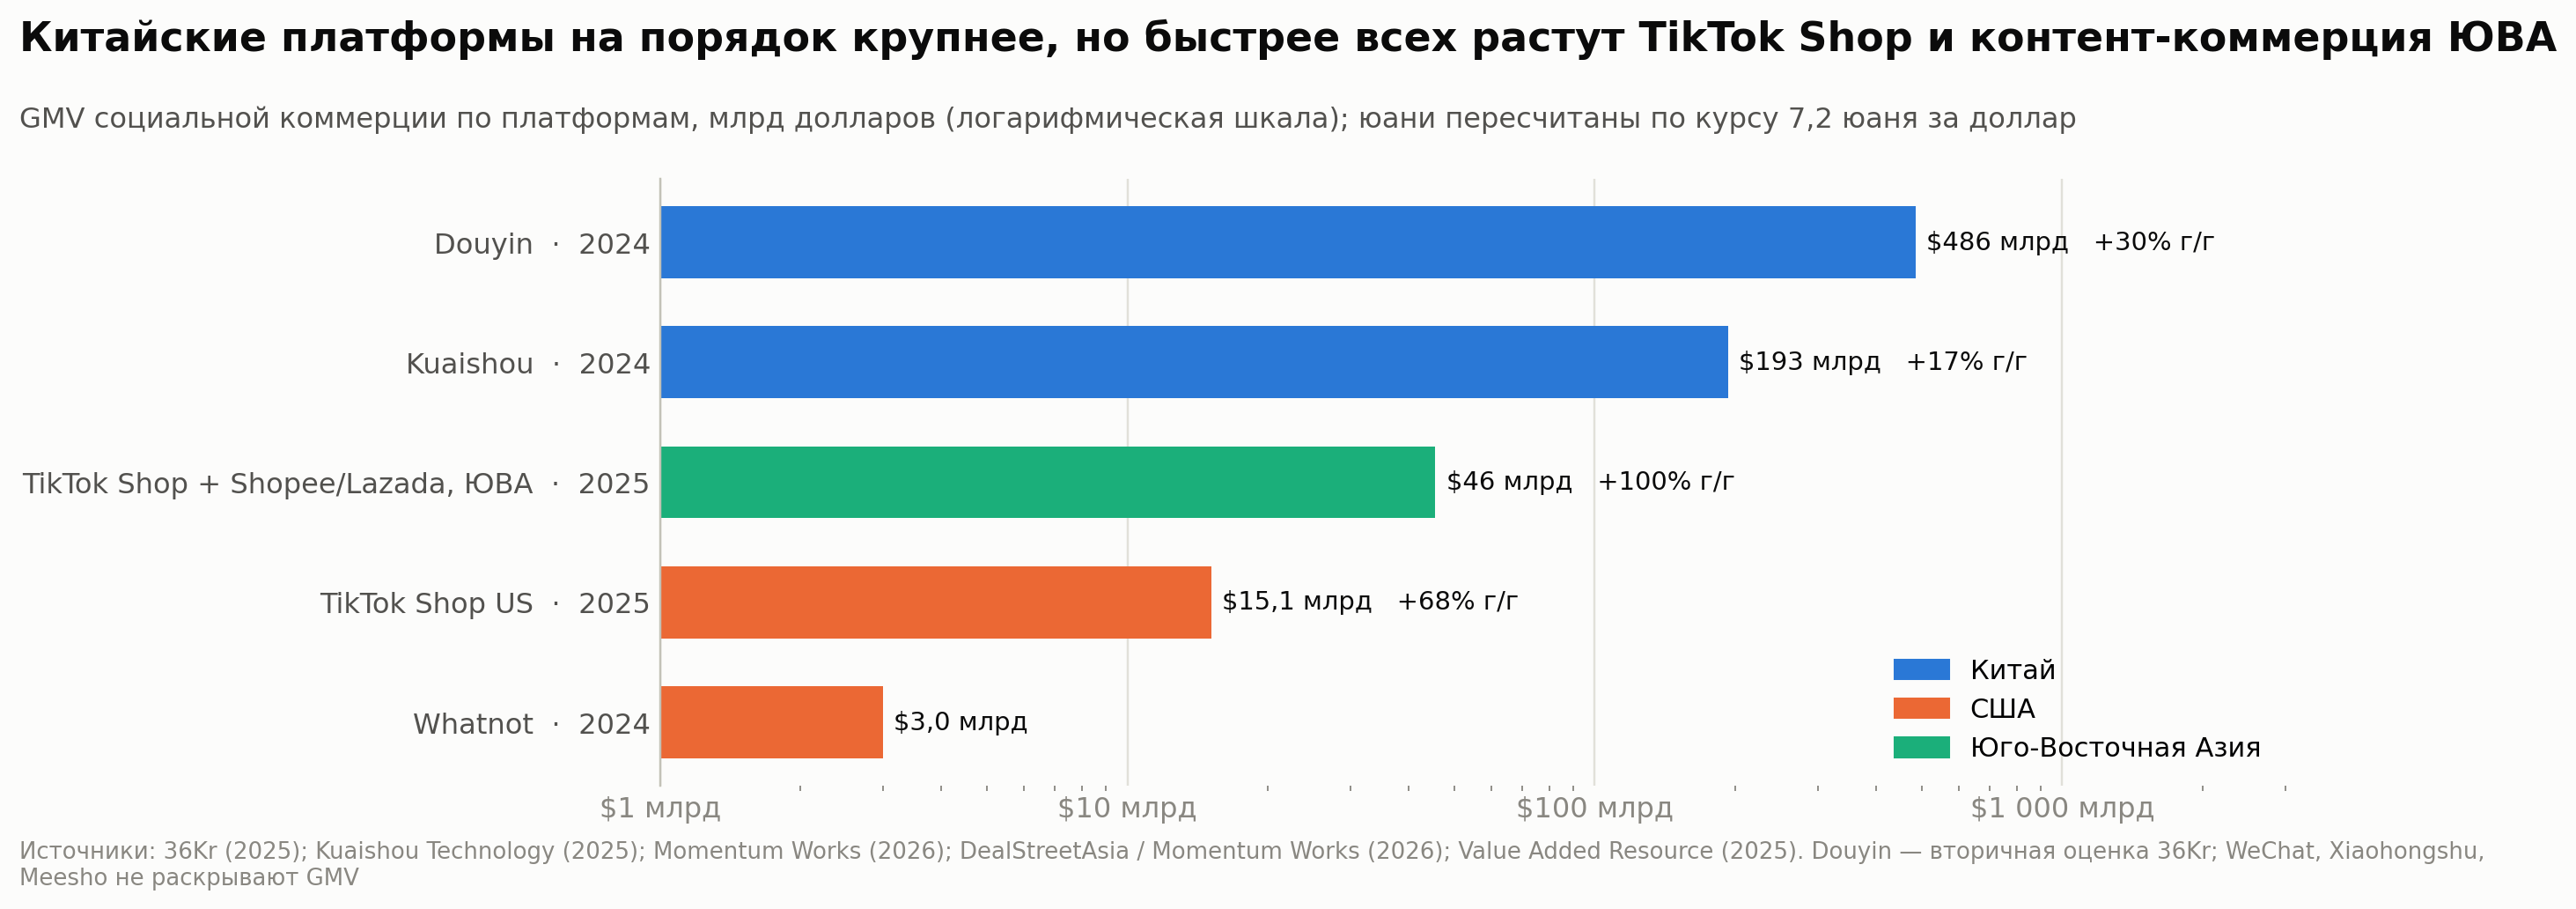

In [4]:
g = cases.dropna(subset=["gmv_usd_bn"]).sort_values("gmv_usd_bn")
fig, ax = plt.subplots(figsize=(12, 4.6))
col = {"Китай": CAT[0], "США": CAT[1], "Юго-Восточная Азия": CAT[2]}
bars = ax.barh(g.platform + "  ·  " + g.year.astype(str), g.gmv_usd_bn, color=[col.get(m, GREY) for m in g.market], height=0.6)
hlabels(ax, bars, [f"${ru(v, 1 if v < 20 else 0)} млрд" + (f"   +{ru(r)}% г/г" if pd.notna(r) else "") for v, r in zip(g.gmv_usd_bn, g.growth_pct)])
ax.set_xscale("log"); ax.set_xlim(1, 3000); hgrid(ax)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${ru(v)} млрд"))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in col.items()], loc="lower right")
finish(fig, "Китайские платформы на порядок крупнее, но быстрее всех растут TikTok Shop и контент-коммерция ЮВА",
       "GMV социальной коммерции по платформам, млрд долларов (логарифмическая шкала); юани пересчитаны по курсу 7,2 юаня за доллар",
       "Источники: " + cite("S01;S03;S06;S07;S22") + ". Douyin — вторичная оценка 36Kr; WeChat, Xiaohongshu, Meesho не раскрывают GMV",
       name="01_gmv_scale")

## 2. Откуда приходит GMV: контент, витрина, эфиры

Ключевой вопрос для роли Маркета ВКонтакте: работает ли «витрина» сама по себе. У лидеров GMV делится между контентом (видео, эфиры) и поиском/витриной, но **витрина питается трафиком из контента**, а не живёт отдельно. Instagram попробовал отдельную вкладку магазина и свернул её.

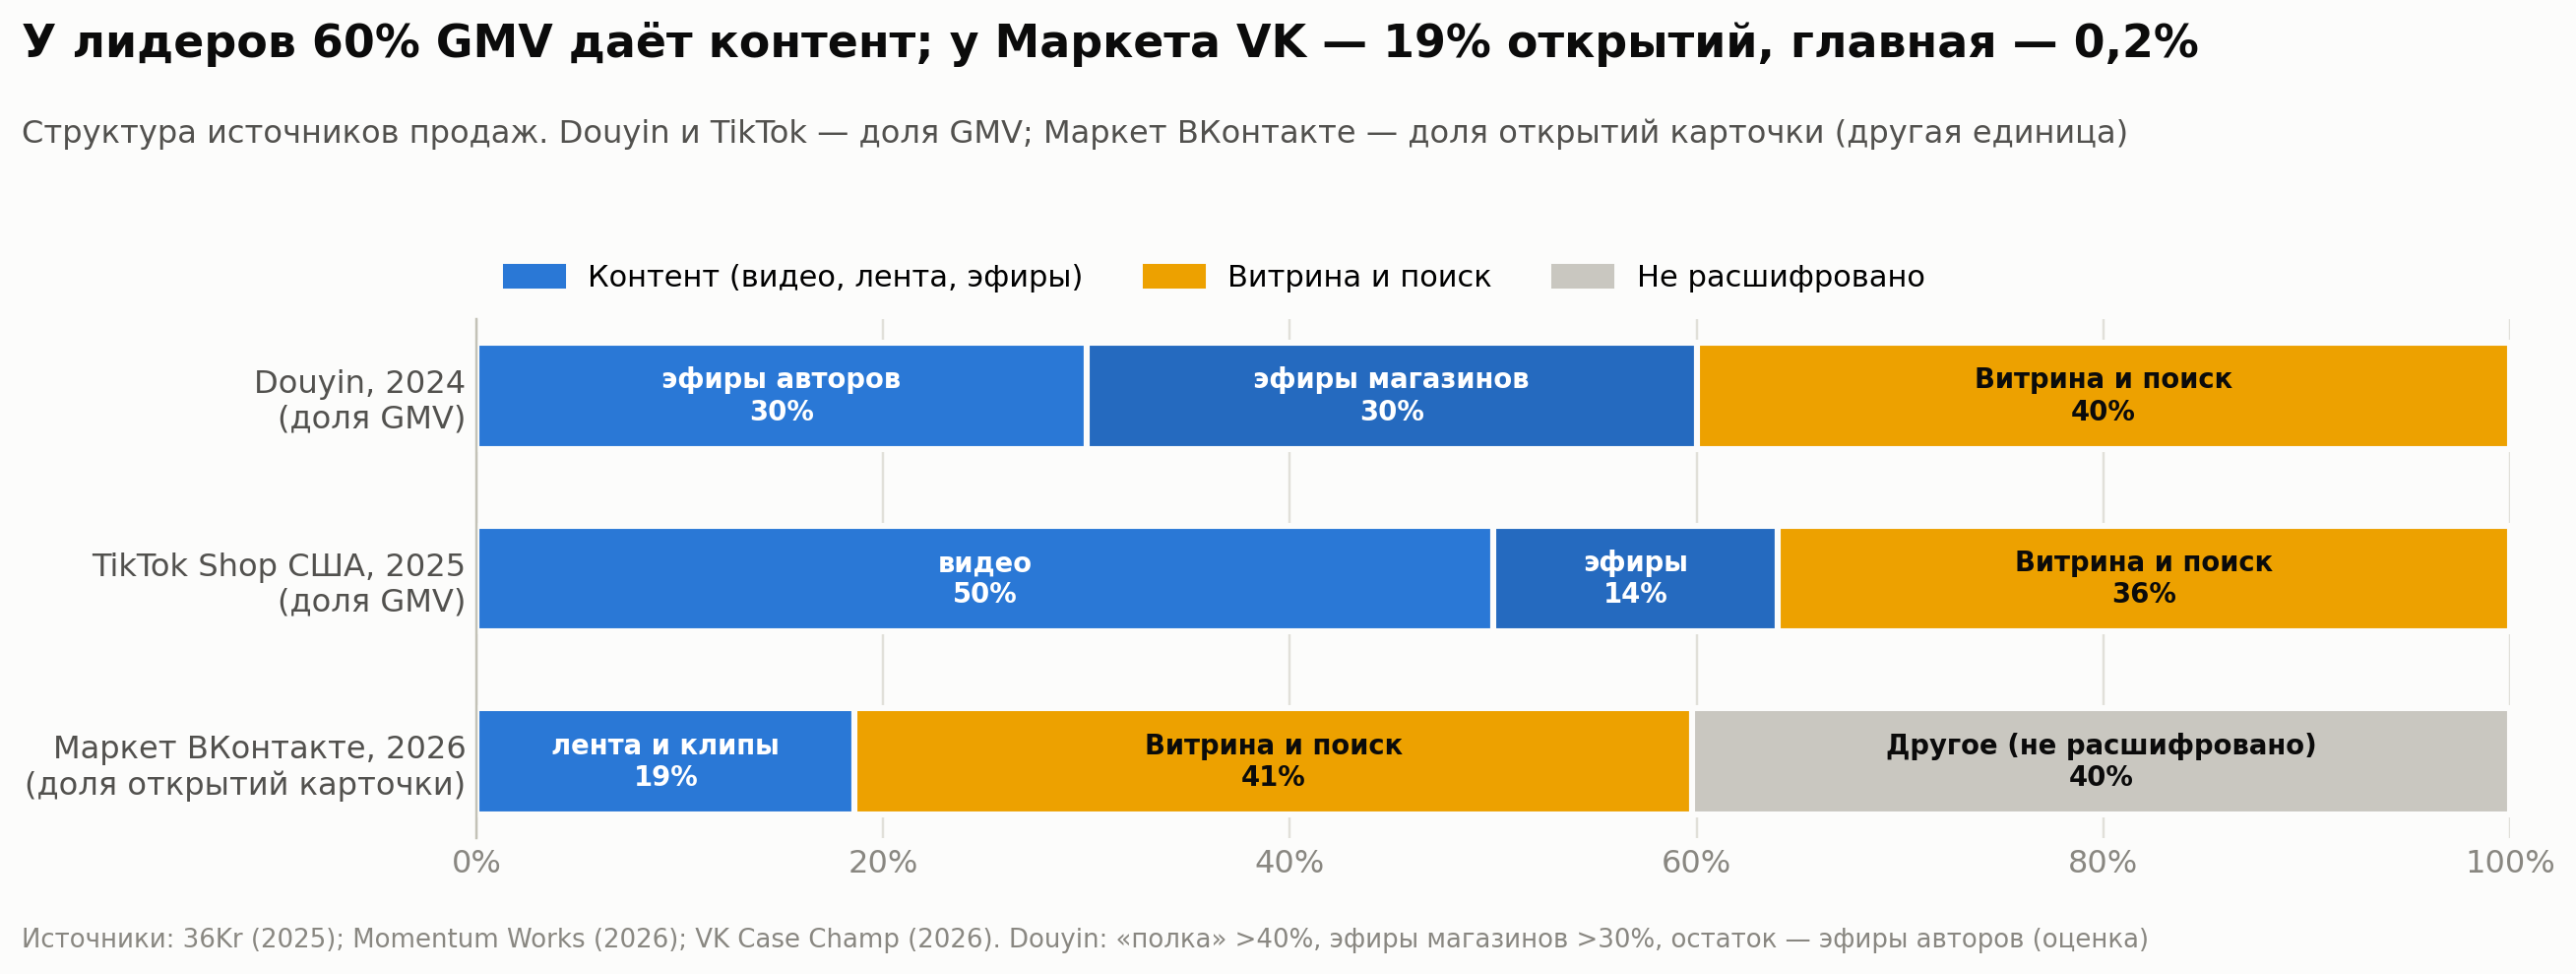

In [5]:
mix = {
    "Douyin, 2024\n(доля GMV)": {"Контент: эфиры авторов": 30, "Контент: эфиры магазинов": 30, "Витрина и поиск": 40},
    "TikTok Shop США, 2025\n(доля GMV)": {"Контент: видео": 50, "Контент: эфиры": 14, "Витрина и поиск": 36},
    "Маркет ВКонтакте, 2026\n(доля открытий карточки)": {"Контент: лента и клипы": 18.6, "Витрина и поиск": 39.1 + 1.9 + 0.2, "Другое (не расшифровано)": 40.2},
}
COLS = {"Контент: эфиры авторов": CAT[0], "Контент: эфиры магазинов": SEQ[4], "Контент: видео": CAT[0], "Контент: эфиры": SEQ[4],
        "Контент: лента и клипы": CAT[0], "Витрина и поиск": CAT[3], "Другое (не расшифровано)": GREY}
fig, ax = plt.subplots(figsize=(12, 4.4))
for i, (row, parts) in enumerate(mix.items()):
    left = 0
    for k, v in parts.items():
        ax.barh(i, v, left=left, color=COLS[k], height=0.58, edgecolor=SURF, linewidth=2)
        ax.text(left + v / 2, i, f"{k.split(': ')[-1]}\n{ru(v, 0)}%", ha="center", va="center", fontsize=9,
                color=INK if COLS[k] in (CAT[3], GREY) else "white", fontweight="bold")
        left += v
ax.set_yticks(range(len(mix)), list(mix)); ax.invert_yaxis(); ax.set_xlim(0, 100); hgrid(ax)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(100))
ax.legend(handles=[Patch(color=CAT[0], label="Контент (видео, лента, эфиры)"), Patch(color=CAT[3], label="Витрина и поиск"), Patch(color=GREY, label="Не расшифровано")],
          ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
finish(fig, "У лидеров 60% GMV даёт контент; у Маркета VK — 19% открытий, главная — 0,2%",
       "Структура источников продаж. Douyin и TikTok — доля GMV; Маркет ВКонтакте — доля открытий карточки (другая единица)",
       "Источники: " + cite("S01;S06;S43") + ". Douyin: «полка» >40%, эфиры магазинов >30%, остаток — эфиры авторов (оценка)",
       top=0.78, name="02_gmv_mix")

In [6]:
lessons = pd.DataFrame([
    ["Instagram", "2022–2023", "Свернули live shopping, убрали вкладку Shop из навигации", "Отдельная витрина не собирала трафик; фокус вернули на рекламу и контент", "S18;S19"],
    ["Facebook", "2023–2024", "Магазины без чекаута закрыты; при этом 77,7% покупателей FB покупают на Marketplace и 14,2% — в Shops", "Люди покупают там, где есть локальные объявления и переписка", "S20;S21"],
    ["Douyin", "2024", "Поиск и витрина («полка») выросли до >40% GMV", "Витрина работает как продолжение контента: люди ищут то, что увидели", "S01"],
    ["Маркет ВКонтакте", "2026", "Главная Маркета даёт 0,2% открытий, витрины сообществ — 39%", "Повтор сценария Instagram: точка входа — сообщество и контент", "S43"],
], columns=["Платформа", "Когда", "Что произошло", "Вывод", "Источник"])
lessons.style.hide(axis="index").set_properties(**{"text-align": "left", "vertical-align": "top"})

Платформа,Когда,Что произошло,Вывод,Источник
Instagram,2022–2023,"Свернули live shopping, убрали вкладку Shop из навигации",Отдельная витрина не собирала трафик; фокус вернули на рекламу и контент,S18;S19
Facebook,2023–2024,"Магазины без чекаута закрыты; при этом 77,7% покупателей FB покупают на Marketplace и 14,2% — в Shops","Люди покупают там, где есть локальные объявления и переписка",S20;S21
Douyin,2024,Поиск и витрина («полка») выросли до >40% GMV,"Витрина работает как продолжение контента: люди ищут то, что увидели",S01
Маркет ВКонтакте,2026,"Главная Маркета даёт 0,2% открытий, витрины сообществ — 39%",Повтор сценария Instagram: точка входа — сообщество и контент,S43


## 3. Кто продаёт: МСБ, концентрация и «первая продажа»

В датасете VK 93% товарных сообществ не получили ни одного заказа за месяц, а топ-10 дают 54% заказов. Это не особенность VK: у TikTok Shop в США больше половины магазинов без продаж, а 1% продавцов делает 60% GMV. Разница в том, **что платформы делают с длинным хвостом**.

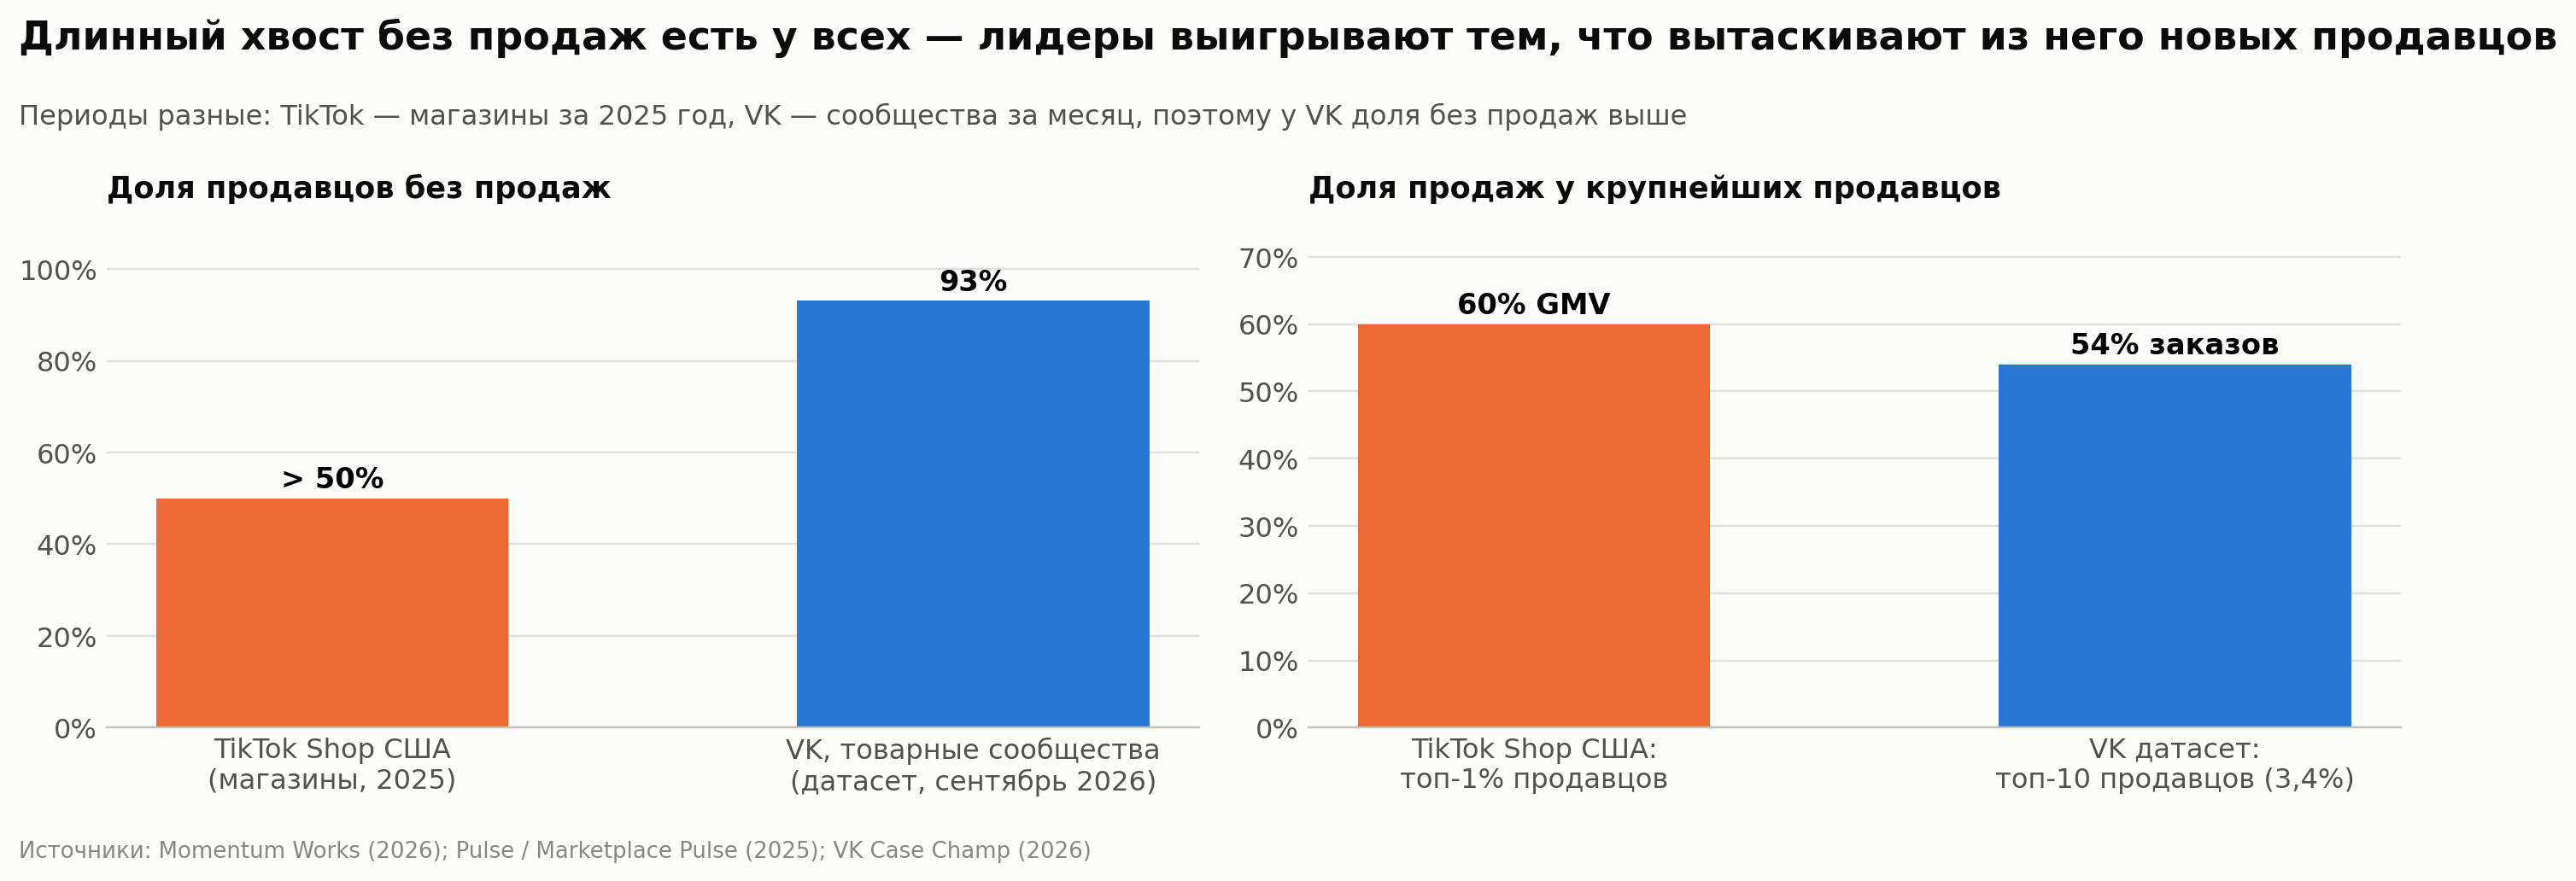

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
d = pd.DataFrame({"Платформа": ["TikTok Shop США\n(магазины, 2025)", "VK, товарные сообщества\n(датасет, сентябрь 2026)"],
                  "v": [50, 93.1]})
bars = ax.bar(d["Платформа"], d.v, color=[PARTNER, VK], width=0.55)
for b, t in zip(bars, ["> 50%", "93%"]):
    ax.annotate(t, (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, 110); ax.yaxis.set_major_formatter(mtick.PercentFormatter(100)); ax.set_title("Доля продавцов без продаж")
ax.tick_params(axis="x", colors=INK2)
ax = axes[1]
d = pd.DataFrame({"k": ["TikTok Shop США:\nтоп-1% продавцов", "VK датасет:\nтоп-10 продавцов (3,4%)"], "v": [60, 54]})
bars = ax.bar(d.k, d.v, color=[PARTNER, VK], width=0.55)
for b, t in zip(bars, ["60% GMV", "54% заказов"]):
    ax.annotate(t, (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, 75); ax.yaxis.set_major_formatter(mtick.PercentFormatter(100)); ax.set_title("Доля продаж у крупнейших продавцов")
ax.tick_params(axis="x", colors=INK2)
finish(fig, "Длинный хвост без продаж есть у всех — лидеры выигрывают тем, что вытаскивают из него новых продавцов",
       "Периоды разные: TikTok — магазины за 2025 год, VK — сообщества за месяц, поэтому у VK доля без продаж выше",
       "Источники: " + cite("S06;S10;S43"), name="03_long_tail")

In [8]:
prog = pd.DataFrame([
    ["Kuaishou", "Программа трафика 100 млрд юаней для новых продавцов; Golden Bounty, Set Sail", "Новые продавцы +30% г/г (Q3 2024)", "S04;S40"],
    ["Xiaohongshu", "Ставка на МСБ и эфиры самих продавцов; объединили операционку байеров и продавцов", "Новые продавцы ×8,1 за 2024; GMV МСБ +436% (H1 2024)", "S14;S15"],
    ["Douyin", "Программа для промышленных кластеров (с 2022): фабрики продают напрямую в своих эфирах", "1,5 млн продавцов кластеров; 90 тыс.+ МСБ прошли 1 млн юаней через свои эфиры", "S01;S02"],
    ["Meesho", "Нулевая комиссия, продажа через ссылки в мессенджерах", "300 тыс. новых продавцов за H1 2024; 80% покупателей из небольших городов", "S16;S17"],
    ["TikTok Shop", "Аффилиатная программа: 15,4 млн авторов продают чужие товары за комиссию", "~42% GMV через авторов (оценка)", "S06"],
], columns=["Платформа", "Что сделали для новых продавцов", "Результат", "Источник"])
prog.style.hide(axis="index").set_properties(**{"text-align": "left", "vertical-align": "top"})

Платформа,Что сделали для новых продавцов,Результат,Источник
Kuaishou,"Программа трафика 100 млрд юаней для новых продавцов; Golden Bounty, Set Sail",Новые продавцы +30% г/г (Q3 2024),S04;S40
Xiaohongshu,Ставка на МСБ и эфиры самих продавцов; объединили операционку байеров и продавцов,"Новые продавцы ×8,1 за 2024; GMV МСБ +436% (H1 2024)",S14;S15
Douyin,Программа для промышленных кластеров (с 2022): фабрики продают напрямую в своих эфирах,"1,5 млн продавцов кластеров; 90 тыс.+ МСБ прошли 1 млн юаней через свои эфиры",S01;S02
Meesho,"Нулевая комиссия, продажа через ссылки в мессенджерах",300 тыс. новых продавцов за H1 2024; 80% покупателей из небольших городов,S16;S17
TikTok Shop,"Аффилиатная программа: 15,4 млн авторов продают чужие товары за комиссию",~42% GMV через авторов (оценка),S06


## 4. Какие авторы продают и кому доверяют

Два независимых сигнала говорят одно и то же: **небольшие авторы и обычные пользователи продают лучше охватных блогеров и аккаунтов брендов.** Вовлечённость падает с ростом аудитории, а российские покупатели больше доверяют друзьям и людям с личным опытом, чем официальным аккаунтам магазинов.

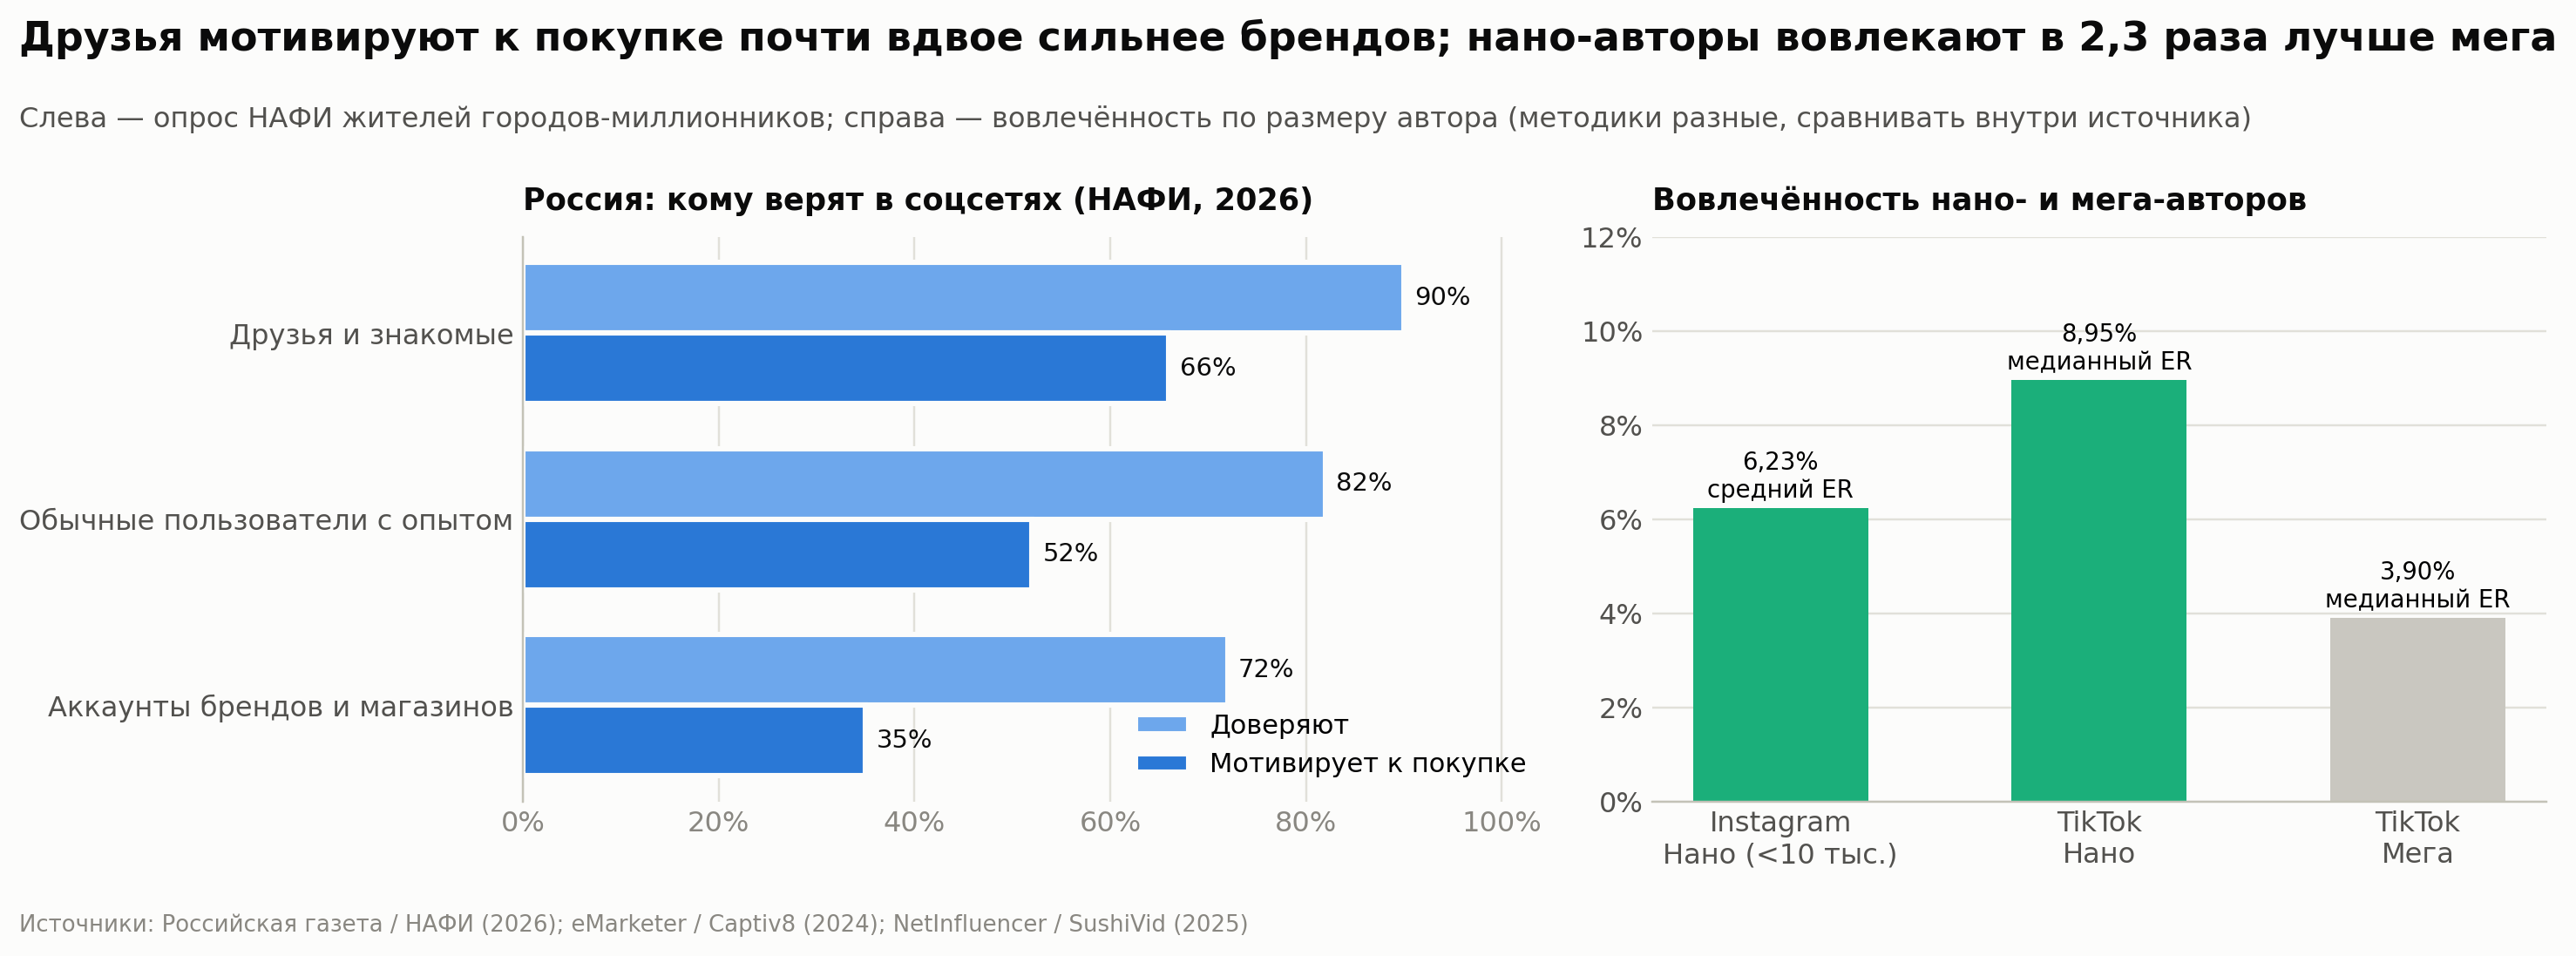

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.9), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
t = nafi[nafi.block == "Источник"].pivot(index="item", columns="metric", values="value_pct")
t = t.reindex(["Друзья и знакомые", "Обычные пользователи с опытом", "Аккаунты брендов и магазинов"])
y = np.arange(len(t)); h = 0.38
b1 = ax.barh(y - h / 2, t["Доверяют"], h, color=SEQ[2], label="Доверяют", edgecolor=SURF, linewidth=2)
b2 = ax.barh(y + h / 2, t["Мотивирует к покупке"], h, color=VK, label="Мотивирует к покупке", edgecolor=SURF, linewidth=2)
hlabels(ax, b1, [f"{v}%" for v in t["Доверяют"]]); hlabels(ax, b2, [f"{v}%" for v in t["Мотивирует к покупке"]])
ax.set_yticks(y, t.index); ax.invert_yaxis(); ax.set_xlim(0, 105); hgrid(ax)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(100)); ax.legend(loc="lower right")
ax.set_title("Россия: кому верят в соцсетях (НАФИ, 2026)")
ax = axes[1]
c = creators.copy(); c["label"] = c.platform + "\n" + c.tier
bars = ax.bar(c.label, c.engagement_pct, color=[CAT[2], CAT[2], GREY], width=0.55)
for b, v, mtr in zip(bars, c.engagement_pct, c.metric):
    ax.annotate(f"{ru(v, 2)}%\n{mtr}", (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax.set_ylim(0, 12); ax.yaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0)); ax.tick_params(axis="x", colors=INK2)
ax.set_title("Вовлечённость нано- и мега-авторов")
finish(fig, "Друзья мотивируют к покупке почти вдвое сильнее брендов; нано-авторы вовлекают в 2,3 раза лучше мега",
       "Слева — опрос НАФИ жителей городов-миллионников; справа — вовлечённость по размеру автора (методики разные, сравнивать внутри источника)",
       "Источники: " + cite("S25;S35;S36"), name="04_trust_creators")

**Что это значит для авторов VK.** У шопсов уже 42 тыс.+ авторов и 1,6 млрд ₽ выплат за год, лидеры — мода, дом, путешествия, авто (S23). Но заказы уходят на Ozon. Механика оплаты за результат работает; её логично открыть для **собственных товарных сообществ VK**, сделав ставку на нано- и микроавторов и клиентов продавца (отзывы, «посоветуй другу»).

## 5. Кто покупает: возраст и пол

Соцкоммерция везде моложе классического e-commerce: Gen Z и миллениалы дают 62–70% трат. Женщины чаще покупают после контента. Покупатели Маркета ВКонтакте в датасете совпадают с этим профилем: 73% женщин, 25–34 лет — 28% против 17% у Партнёра.

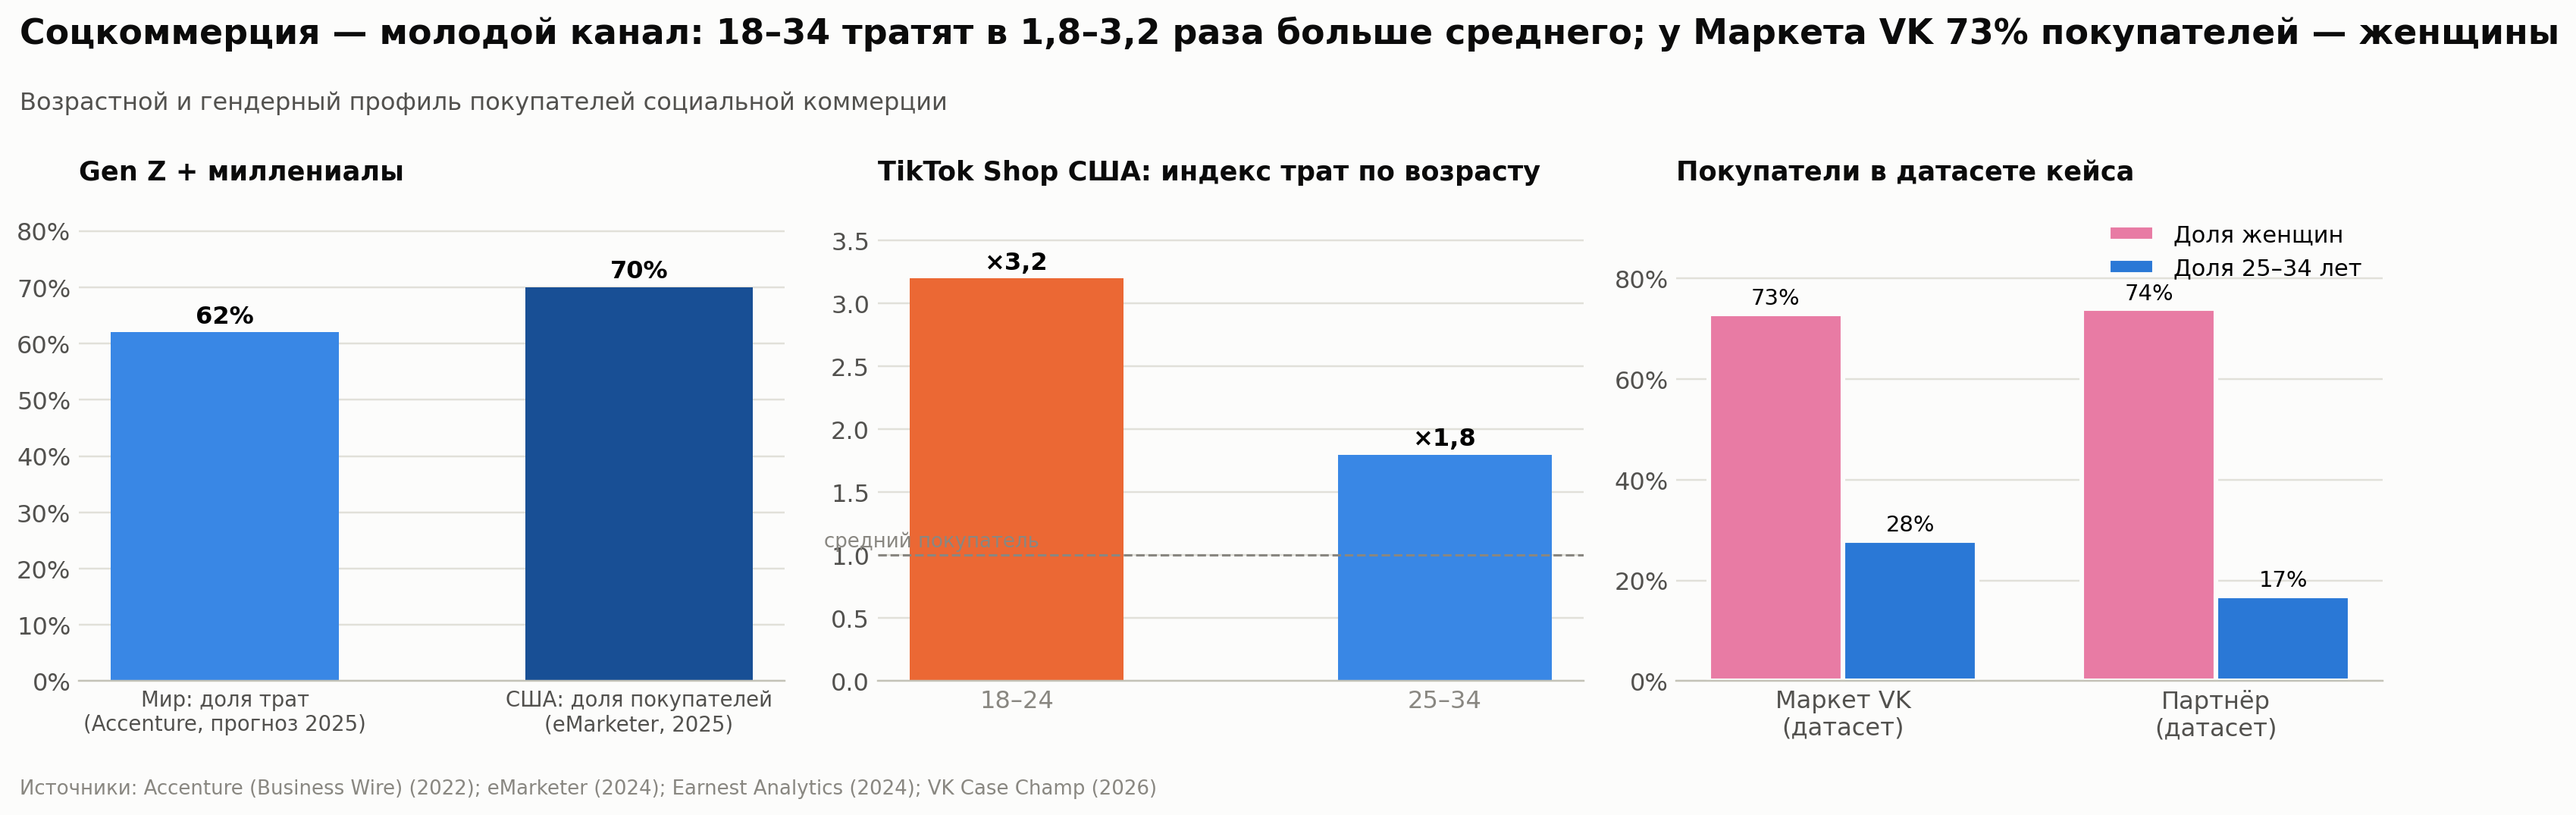

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.8), gridspec_kw={"width_ratios": [1, 1, 1]})
ax = axes[0]
d = pd.DataFrame({"k": ["Мир: доля трат\n(Accenture, прогноз 2025)", "США: доля покупателей\n(eMarketer, 2025)"], "v": [62, 70]})
bars = ax.bar(d.k, d.v, color=[SEQ[3], SEQ[5]], width=0.55)
for b, v in zip(bars, d.v):
    ax.annotate(f"{v}%", (b.get_x() + b.get_width() / 2, v), xytext=(0, 4), textcoords="offset points", ha="center", fontweight="bold")
ax.set_ylim(0, 85); ax.yaxis.set_major_formatter(mtick.PercentFormatter(100)); ax.set_title("Gen Z + миллениалы")
ax.tick_params(axis="x", colors=INK2, labelsize=9)
ax = axes[1]
d = demo[demo.metric == "Индекс трат в TikTok Shop vs средний"]
bars = ax.bar(d.segment, d.value, color=[CAT[1], SEQ[3]], width=0.5)
for b, v in zip(bars, d.value):
    ax.annotate(f"×{ru(v, 1)}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 4), textcoords="offset points", ha="center", fontweight="bold")
ax.axhline(1, color=MUTED, ls="--", lw=1); ax.text(-0.45, 1.07, "средний покупатель", color=MUTED, fontsize=8.5, ha="left")
ax.set_ylim(0, 3.8); ax.set_title("TikTok Shop США: индекс трат по возрасту")
ax = axes[2]
d = pd.DataFrame({"k": ["Маркет VK\n(датасет)", "Партнёр\n(датасет)"], "w": [73, 74], "y": [28, 17]})
x = np.arange(2); w = 0.36
b1 = ax.bar(x - w / 2, d.w, w, color=CAT[4], label="Доля женщин", edgecolor=SURF, linewidth=2)
b2 = ax.bar(x + w / 2, d.y, w, color=VK, label="Доля 25–34 лет", edgecolor=SURF, linewidth=2)
for bs in (b1, b2):
    for b in bs:
        ax.annotate(f"{int(b.get_height())}%", (b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9.5)
ax.set_xticks(x, d.k); ax.set_ylim(0, 95); ax.yaxis.set_major_formatter(mtick.PercentFormatter(100)); ax.legend(loc="upper right")
ax.set_title("Покупатели в датасете кейса"); ax.tick_params(axis="x", colors=INK2)
finish(fig, "Соцкоммерция — молодой канал: 18–34 тратят в 1,8–3,2 раза больше среднего; у Маркета VK 73% покупателей — женщины",
       "Возрастной и гендерный профиль покупателей социальной коммерции",
       "Источники: " + cite("S29;S30;S32;S43"), name="05_buyers")

In [11]:
d = demo[demo.market == "Россия"][["segment", "metric", "value", "unit", "source_id"]]
d.style.hide(axis="index").format({"value": lambda v: ru(v)})

segment,metric,value,unit,source_id
Жители городов-миллионников,"Покупали через соцсети, сообщества, каналы",49,%,S25
Пользователи соцсервисов,Покупали прямо из публикации,46,%,S25
Пользователи соцсервисов,Покупали из публикации неоднократно,27,%,S25
Жители городов-миллионников,Хотят покупать из публикации в 1–2 клика,72,%,S25
Маркет ВКонтакте (датасет),Доля женщин среди покупателей,73,%,S43
Маркет ВКонтакте (датасет),Доля 25–34 среди покупателей,28,%,S43
Партнёр (датасет),Доля 25–34 среди покупателей,17,%,S43


## 6. Что продаётся

Лидируют визуальные товары с невысоким чеком и импульсной покупкой: красота, одежда, дом, еда. В датасете у Маркета ВКонтакте 70% заказов дают «Продукты питания» и «Хобби», у Партнёра — «Дом и дача» и «Красота». Шопсы VK с товарами Ozon чаще всего продают товары для дома, бытовую химию, косметику и товары для животных (S24).

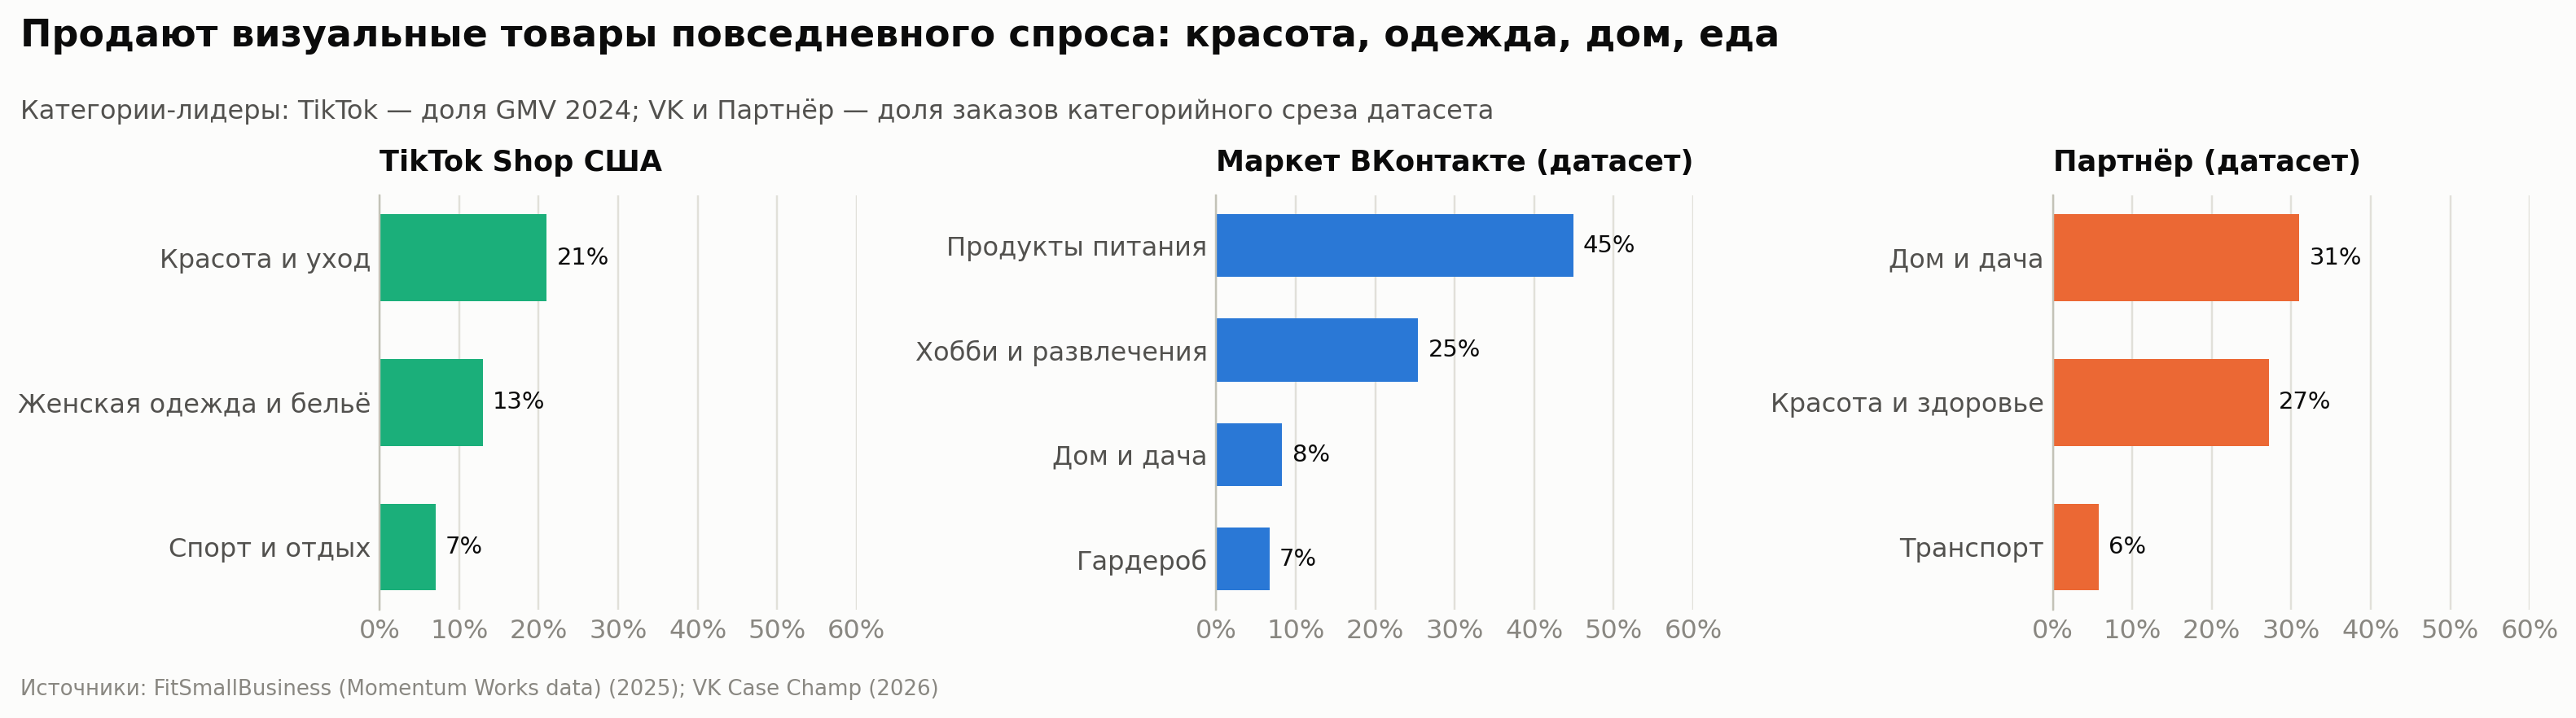

In [12]:
plats = ["TikTok Shop США", "Маркет ВКонтакте (датасет)", "Партнёр (датасет)"]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.9))
for ax, p, c in zip(axes, plats, [CAT[2], VK, PARTNER]):
    d = cats[cats.platform == p].sort_values("share_pct")
    bars = ax.barh(d.category, d.share_pct, color=c, height=0.6)
    hlabels(ax, bars, [f"{ru(v, 0)}%" for v in d.share_pct]); hgrid(ax)
    ax.set_xlim(0, 60); ax.xaxis.set_major_formatter(mtick.PercentFormatter(100)); ax.set_title(p)
finish(fig, "Продают визуальные товары повседневного спроса: красота, одежда, дом, еда",
       "Категории-лидеры: TikTok — доля GMV 2024; VK и Партнёр — доля заказов категорийного среза датасета",
       "Источники: " + cite("S11;S43"), name="06_categories")

## 7. Метрики VK против бенчмарков

Центральная таблица исследования. Для каждой метрики стратегии — значение в датасете VK, ориентир с других рынков и что из этого следует. Предлагаемая **главная метрика** для стратегии: *число товарных сообществ с хотя бы одним заказом, оплаченным внутри VK, за 30 дней* — она прямо отвечает обеим целям брифа (больше продающих бизнесов и больше заказов внутри VK).

In [13]:
bench = pd.DataFrame([
    ["Продающие бизнесы", "Доля продавцов без продаж", "93% товарных сообществ (месяц)", ">50% магазинов TikTok Shop США (год)", "Проблема первой продажи общая; нужен отдельный путь для новичков", "S43;S06"],
    ["Продающие бизнесы", "Концентрация продаж", "Топ-10 (3,4% продавцов) = 54% заказов", "Топ-1% = 60% GMV TikTok Shop США", "Норма для рынка; цель — расширять базу, а не растить лидеров", "S43;S10"],
    ["Заказы внутри VK", "Конверсия открытие → заказ", "0,21% Маркет VK", "5,67% Партнёр; до ~30% в live-коммерции Китая", "Узкое место — оформление и оплата, а не охват", "S43;S37"],
    ["Заказы внутри VK", "Доля заказов, оплаченных на платформе", "1,2% Маркет VK", "Douyin, TikTok Shop, WeChat — оплата внутри приложения по умолчанию", "Встроенная оплата — условие цели «заказы внутри VK»", "S43;S01;S06"],
    ["Трафик", "Доля продаж из контента", "18,6% открытий из ленты и клипов", "60% GMV Douyin; 64% GMV TikTok Shop США; 32% GMV ЮВА", "Контент недоиспользован как источник продаж", "S43;S01;S06;S09"],
    ["Трафик", "Доля общей витрины", "0,2% открытий с главной Маркета", "Instagram убрал вкладку Shop (2023)", "Отдельная витрина не точка входа", "S43;S18"],
    ["Авторы", "Доля GMV через авторов", "Нет данных для своих продавцов; у Партнёра 94,8% открытий из реферальных постов", "~42% GMV TikTok Shop США; ~30% Douyin", "Аффилиатов стоит открыть для товарных сообществ VK", "S43;S06;S01"],
    ["Покупатели", "Ядро аудитории", "73% женщины; 25–34 — 28%", "Gen Z + миллениалы = 62–70% трат", "Профиль совпадает с мировым ядром соцкоммерции", "S43;S29;S30"],
], columns=["Цель", "Метрика", "VK (датасет кейса)", "Бенчмарк", "Вывод", "Источники"])
bench.style.hide(axis="index").set_properties(**{"text-align": "left", "vertical-align": "top"})

Цель,Метрика,VK (датасет кейса),Бенчмарк,Вывод,Источники
Продающие бизнесы,Доля продавцов без продаж,93% товарных сообществ (месяц),>50% магазинов TikTok Shop США (год),Проблема первой продажи общая; нужен отдельный путь для новичков,S43;S06
Продающие бизнесы,Концентрация продаж,"Топ-10 (3,4% продавцов) = 54% заказов",Топ-1% = 60% GMV TikTok Shop США,"Норма для рынка; цель — расширять базу, а не растить лидеров",S43;S10
Заказы внутри VK,Конверсия открытие → заказ,"0,21% Маркет VK","5,67% Партнёр; до ~30% в live-коммерции Китая","Узкое место — оформление и оплата, а не охват",S43;S37
Заказы внутри VK,"Доля заказов, оплаченных на платформе","1,2% Маркет VK","Douyin, TikTok Shop, WeChat — оплата внутри приложения по умолчанию",Встроенная оплата — условие цели «заказы внутри VK»,S43;S01;S06
Трафик,Доля продаж из контента,"18,6% открытий из ленты и клипов",60% GMV Douyin; 64% GMV TikTok Shop США; 32% GMV ЮВА,Контент недоиспользован как источник продаж,S43;S01;S06;S09
Трафик,Доля общей витрины,"0,2% открытий с главной Маркета",Instagram убрал вкладку Shop (2023),Отдельная витрина не точка входа,S43;S18
Авторы,Доля GMV через авторов,"Нет данных для своих продавцов; у Партнёра 94,8% открытий из реферальных постов",~42% GMV TikTok Shop США; ~30% Douyin,Аффилиатов стоит открыть для товарных сообществ VK,S43;S06;S01
Покупатели,Ядро аудитории,73% женщины; 25–34 — 28%,Gen Z + миллениалы = 62–70% трат,Профиль совпадает с мировым ядром соцкоммерции,S43;S29;S30


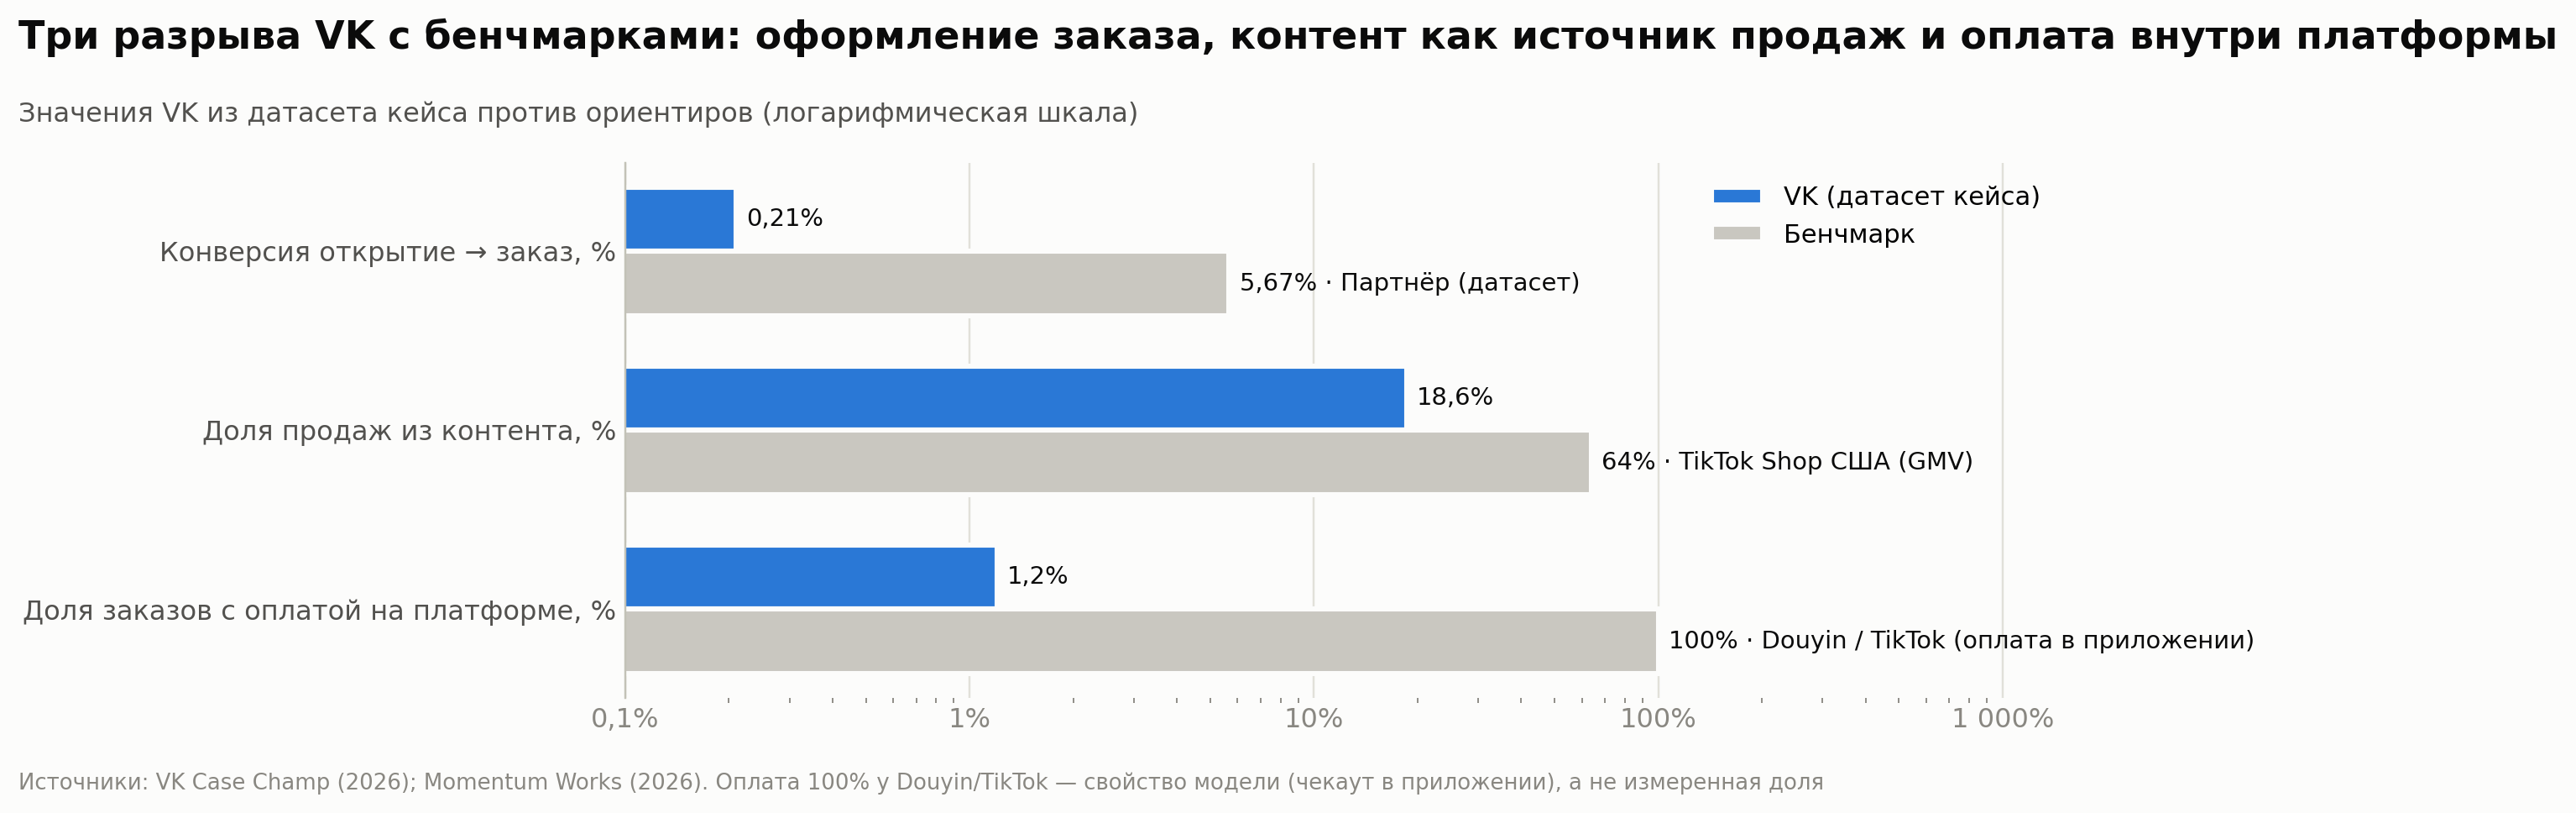

In [14]:
fig, ax = plt.subplots(figsize=(12, 4.3))
rows = [("Конверсия открытие → заказ, %", 0.21, 5.67, "Партнёр (датасет)"),
        ("Доля продаж из контента, %", 18.6, 64, "TikTok Shop США (GMV)"),
        ("Доля заказов с оплатой на платформе, %", 1.2, 100, "Douyin / TikTok (оплата в приложении)")]
y = np.arange(len(rows)); h = 0.36
b1 = ax.barh(y - h / 2, [r[1] for r in rows], h, color=VK, label="VK (датасет кейса)", edgecolor=SURF, linewidth=2)
b2 = ax.barh(y + h / 2, [r[2] for r in rows], h, color=GREY, label="Бенчмарк", edgecolor=SURF, linewidth=2)
hlabels(ax, b1, [f"{ru(r[1], 2 if r[1] < 1 else 1)}%" for r in rows])
hlabels(ax, b2, [f"{ru(r[2], 2 if r[2] < 10 else 0)}% · {r[3]}" for r in rows])
ax.set_yticks(y, [r[0] for r in rows]); ax.invert_yaxis(); ax.set_xscale("log"); ax.set_xlim(0.1, 1500); hgrid(ax)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{ru(v, 1 if v < 1 else 0)}%")); ax.legend(loc="upper right")
finish(fig, "Три разрыва VK с бенчмарками: оформление заказа, контент как источник продаж и оплата внутри платформы",
       "Значения VK из датасета кейса против ориентиров (логарифмическая шкала)",
       "Источники: " + cite("S43;S06") + ". Оплата 100% у Douyin/TikTok — свойство модели (чекаут в приложении), а не измеренная доля",
       name="07_gaps")

## 8. Какие модели подходят VK

Оценка команды по пяти критериям (1 — слабо, 5 — сильно). Это **экспертная оценка**, а не измерение: её стоит обсудить в команде и при необходимости поменять баллы в ячейке ниже — график и итог пересчитаются.

| Критерий | Что оцениваем |
|---|---|
| Опора на активы VK | Есть ли у VK нужное сейчас: сообщества, контент, авторы, сообщения, приём заказов и онлайн-оплата |
| Подтверждено датасетом | Есть ли в данных кейса признаки, что модель сработает |
| Масштаб на МСБ | Подходит ли длинному хвосту небольших продавцов |
| Заказы внутри VK | Остаётся ли заказ и оплата на платформе |
| Скорость запуска | Насколько быстро проверить пилотом (5 — быстро) |

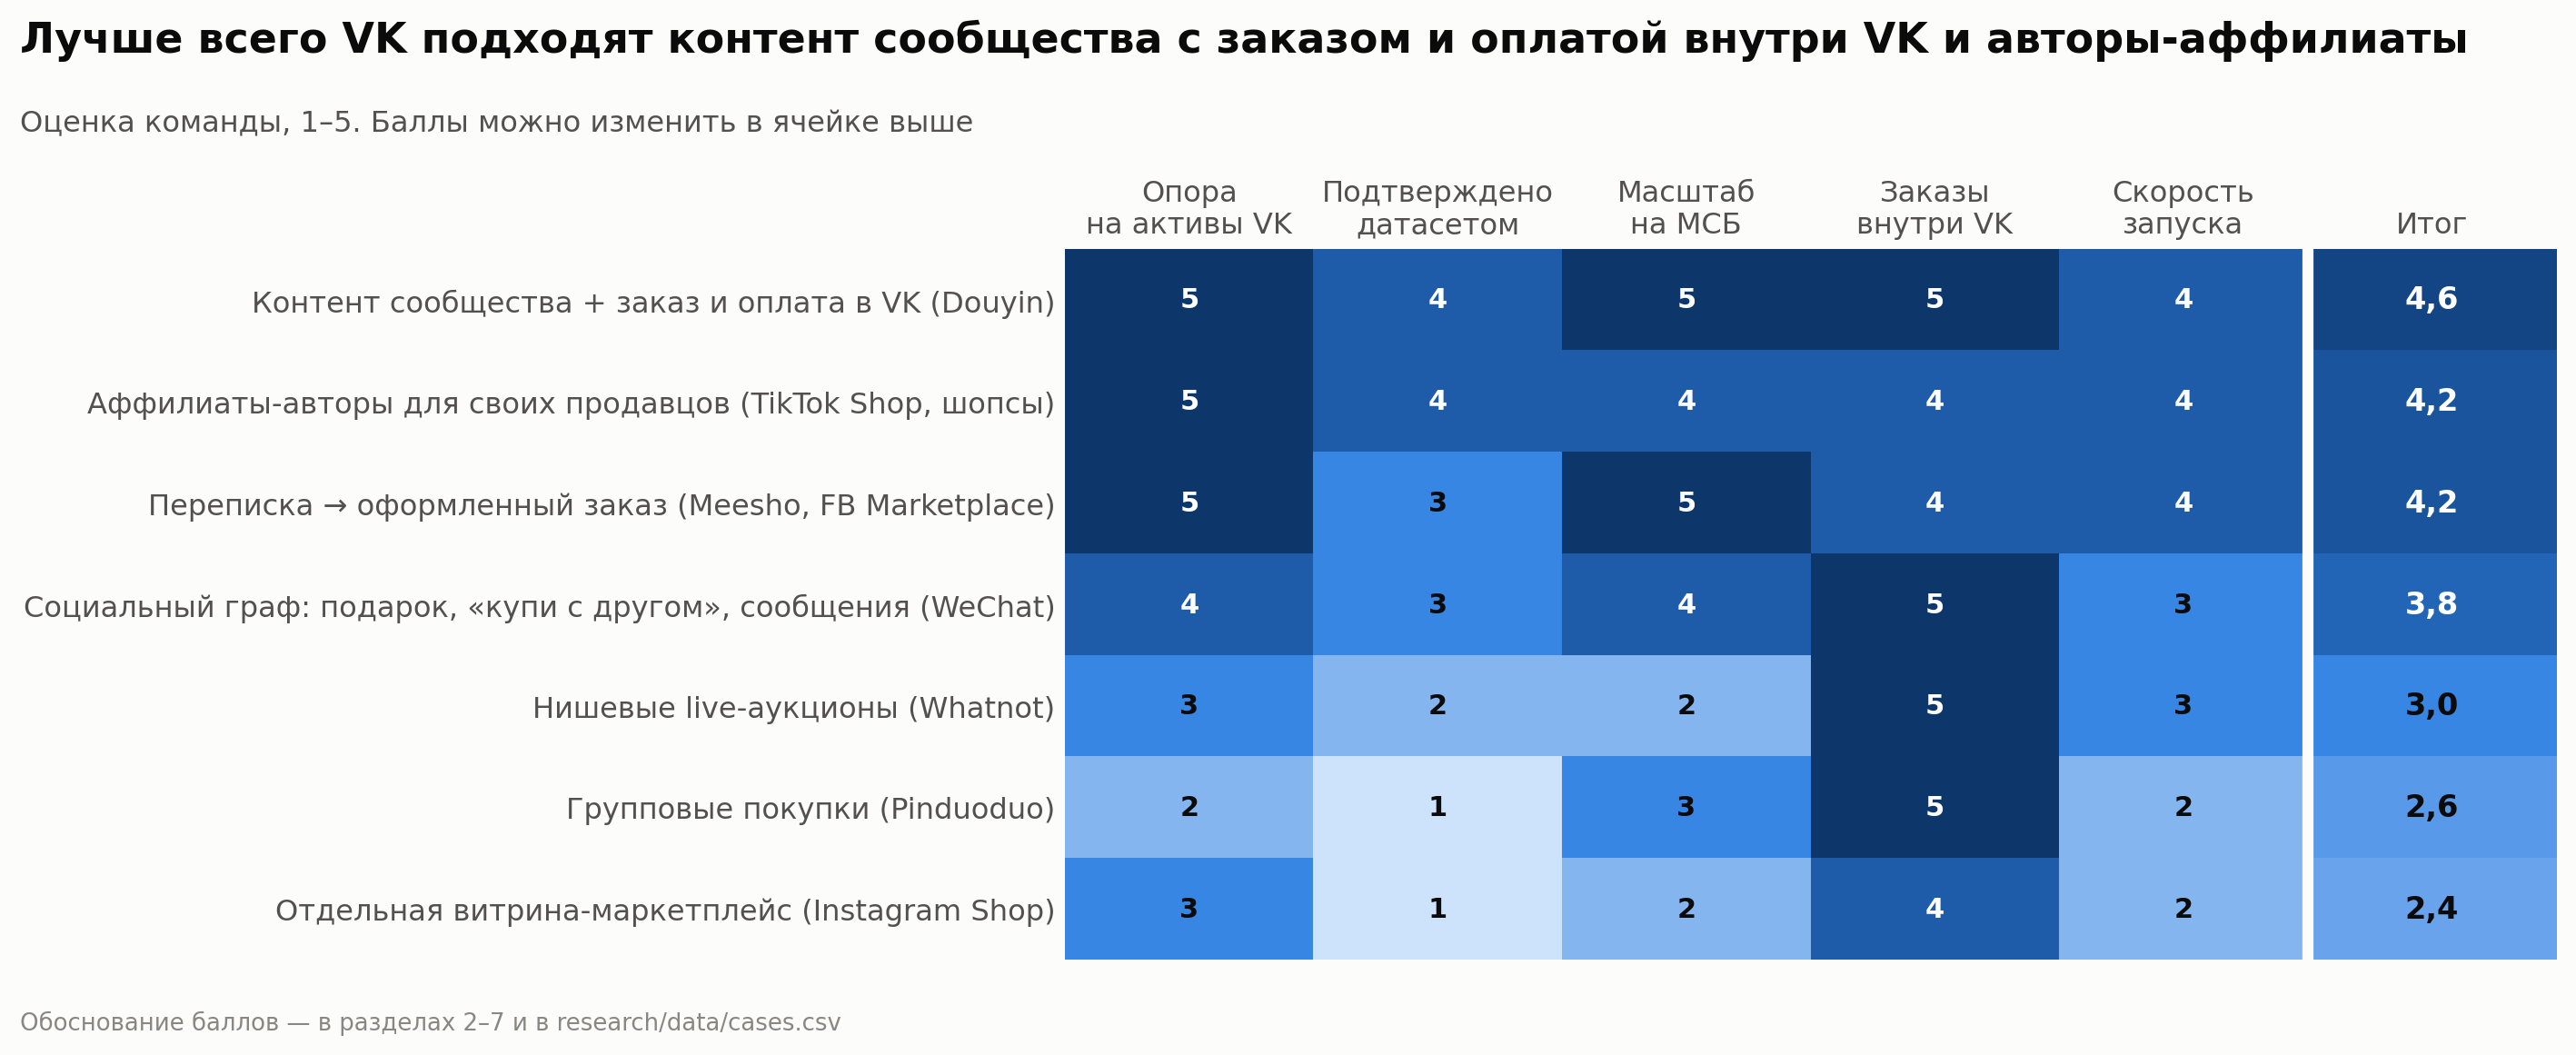

In [15]:
CRIT = ["Опора на активы VK", "Подтверждено датасетом", "Масштаб на МСБ", "Заказы внутри VK", "Скорость запуска"]
fit = pd.DataFrame([
    ["Контент сообщества + заказ и оплата в VK (Douyin)", 5, 4, 5, 5, 4],
    ["Аффилиаты-авторы для своих продавцов (TikTok Shop, шопсы)", 5, 4, 4, 4, 4],
    ["Социальный граф: подарок, «купи с другом», сообщения (WeChat)", 4, 3, 4, 5, 3],
    ["Переписка → оформленный заказ (Meesho, FB Marketplace)", 5, 3, 5, 4, 4],
    ["Групповые покупки (Pinduoduo)", 2, 1, 3, 5, 2],
    ["Нишевые live-аукционы (Whatnot)", 3, 2, 2, 5, 3],
    ["Отдельная витрина-маркетплейс (Instagram Shop)", 3, 1, 2, 4, 2],
], columns=["Модель"] + CRIT).set_index("Модель")
fit["Итог"] = fit[CRIT].mean(axis=1).round(1)
fit = fit.sort_values("Итог", ascending=False)

fig, ax = plt.subplots(figsize=(13, 5.2))
cmap = LinearSegmentedColormap.from_list("seq", SEQ)
M = fit[CRIT + ["Итог"]].values
im = ax.imshow(M, cmap=cmap, vmin=1, vmax=5, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M[i, j]
        ax.text(j, i, ru(v, 1) if j == M.shape[1] - 1 else int(v), ha="center", va="center",
                fontsize=11 if j == M.shape[1] - 1 else 10, fontweight="bold", color="white" if v >= 3.5 else INK)
ax.set_xticks(range(M.shape[1]), [c.replace(" ", "\n", 1) for c in CRIT] + ["Итог"]); ax.set_yticks(range(len(fit)), fit.index)
ax.xaxis.tick_top(); ax.grid(False); ax.spines["bottom"].set_visible(False); ax.tick_params(axis="x", colors=INK2)
ax.axvline(len(CRIT) - 0.5, color=SURF, lw=4)
finish(fig, "Лучше всего VK подходят контент сообщества с заказом и оплатой внутри VK и авторы-аффилиаты",
       "Оценка команды, 1–5. Баллы можно изменить в ячейке выше", "Обоснование баллов — в разделах 2–7 и в research/data/cases.csv",
       top=0.86, name="08_fit_matrix")

## 9. Выводы для презентации

**Слайд «Место VK среди каналов» (бриф, задача 1).** Мировые лидеры соцкоммерции продают там, где человек уже смотрит контент и общается: Douyin и TikTok Shop получают около 60% GMV из видео и эфиров, WeChat растёт на подарках и чатах. Отдельная витрина в соцсети без контента не прижилась (Instagram, 2023). У VK есть всё сразу — сообщества, контент, авторы, сообщения, приём заказов и онлайн-оплата, — но они не связаны в один путь: заказ оформляют в VK, а оплачено внутри VK лишь 1,2% заказов. Это и есть позиционирование: **VK — место, где малый бизнес продаёт своим подписчикам и их друзьям, не уходя на маркетплейс.**

**Слайд «Целевые бизнесы» (задача 2).** Везде выигрывают МСБ, которые сами ведут контент и эфиры: у Douyin >90% бизнесов — МСБ, 90 тыс.+ из них прошли 1 млн юаней через собственные эфиры; Xiaohongshu за год увеличил число новых продавцов в 8 раз. При этом даже у TikTok Shop больше половины магазинов не продают. Целевой сегмент VK — товарные сообщества, которые принимают заказы в VK, но не подключили онлайн-оплату и доставку и не получили ни одного заказа (61% выборки).

**Слайд «Инструменты и авторы» (задача 3).** Продают нано- и микроавторы и обычные пользователи: друзья мотивируют к покупке в России почти вдвое сильнее брендов (66% против 35%). Авторы VK уже заработали 1,6 млрд ₽ на шопсах, но для товаров Ozon. Предложение: открыть аффилиатную механику для собственных продавцов VK и добавить «посоветовать другу / подарить» в карточку.

**Слайд «Роль Маркета» (задача 4).** Маркет — не отдельная витрина, а общая инфраструктура карточки, корзины и оплаты для сообществ, ленты, клипов и сообщений. Аргументы: главная даёт 0,2% открытий; Instagram свернул вкладку магазина; у Douyin витрина растёт как продолжение контента.

**Слайд «Экономика и метрики» (задачи 3, 5).** Главная метрика — число сообществ с заказом, оплаченным внутри VK, за 30 дней. Три разрыва с бенчмарками: конверсия открытие → заказ (0,21% против 5,67%), доля продаж из контента (19% против ~60%), оплата внутри платформы (1,2%).

**Ограничения.** Платформы раскрывают разные показатели; часть чисел — вторичные оценки (помечены `secondary`). Рынки Китая и США отличаются логистикой и платёжной инфраструктурой, поэтому переносим механики, а не абсолютные значения. Матрица в разделе 8 — экспертная оценка команды.

In [16]:
# Полный список источников с уровнем достоверности
sources.style.hide(axis="index").set_properties(**{"text-align": "left"})

source_id,publisher,title,url,published,type
S01,36Kr,"Douyin E-commerce 2024 GMV ~3.5 trn yuan; shelf >40%, store livestream >30%",https://eu.36kr.com/en/p/3166066575158018,2025-01,secondary
S02,Sixth Tone,"Skincare to Seafood, China's Trade Hubs Ride the Livestream Wave (Douyin industrial belts report)",https://www.sixthtone.com/news/1016455,2025-01,research
S03,Kuaishou Technology,Fourth Quarter and Full Year 2024 Financial Results,https://kuaishou.gcs-web.com/news-releases/news-release-details/kuaishou-technology-announces-fourth-quarter-and-full-year-2024,2025-03-25,official
S04,Kuaishou Technology,Third Quarter 2024 Unaudited Financial Results,https://itiger.com/news/2484422166,2024-11,official
S05,Dolphin Research,Kuaishou Q2 2024: monthly active e-commerce buyers 131 mn,https://longportapp.cn/topics/23304657,2024-08,secondary
S06,Momentum Works,TikTok Shop in the U.S. 2025,https://momentum.asia/insights/detail/tiktok-shop-in-the-us-2025,2026-01,research
S07,DealStreetAsia / Momentum Works,TikTok Shop hits $15.1b GMV in US as SEA doubles to $45.6b in 2025,https://cdn.dealstreetasia.com/stories/tiktok-shop-gmv-2025-472662,2026-01,research
S08,Momentum Works (The Low Down),Southeast Asia platform e-commerce reaches US$157.6B in 2025,https://thelowdown.momentum.asia/new-report-southeast-asias-platform-ecommerce-reaches-us157-6b-in-2025-with-top-platforms-expanding-share-to-98-8/,2026,research
S09,e27,Southeast Asia's live commerce boom enters its harder second act (Momentum Works Live Commerce 2026),https://e27.co/southeast-asias-live-commerce-boom-enters-its-harder-second-act-20260908/,2026-09,secondary
S10,Pulse / Marketplace Pulse,"On TikTok Shop, 1% of sellers drive 60% of GMV",https://www.pulse.bot/ecommerce/news/on-tiktok-shop-1-of-sellers-drive-60-of-gmv-bef85eb3-e698-49b0-ac71-1a52b8b48024/,2025,secondary
